# **Практическая работа №3. Сравнительный анализ базовых и ансамблевых методов машинного обучения в задачах классификации текстов**

---

## **Введение**

Отзывы об организациях содержат два источника информации: текст с описанием опыта посетителя и оценку от 1 до 5 звёзд. Их сопоставление позволяет выявить случаи, требующие подробного анализа: неоднозначные тексты, расхождения между содержанием и оценкой, а также ошибки моделей.

Методы классификации текстов применяются для определения тональности и прогнозирования оценки по содержанию отзыва. Результаты объединяются со сведениями об организациях и их координатами, чтобы сравнить отзывы выбранных территорий и отобразить выявленные расхождения на карте.

**🎯 Цель работы:** освоить построение и оценку моделей классификации русскоязычных текстов и применить их к анализу отзывов об организациях с учётом пространственного расположения объектов.

**Задачи работы:**

1. Подготовить текстовые данные и сравнить мешок слов, TF-IDF, Word2Vec, Doc2Vec и современные нейросетевые эмбеддинги.
2. Обучить и сравнить классификаторы тональности, подобрать параметры и оценить качество на тестовой выборке.
3. Построить модель прогнозирования оценки по тексту отзыва с разделением данных по организациям.
4. Сформулировать правило отбора отзывов, в которых текст может расходиться с оценкой, и проверить его по результатам чтения.
5. Собрать отзывы выбранных территорий, подготовить сводку по организациям и карты тональности, оценок и расхождений.
6. Сравнить результаты для двух территорий и сформулировать выводы с учётом качества моделей и ограничений выборки.

**Данные:**

- [RuSentiTweet](https://github.com/sismetanin/rusentitweet) — русскоязычные сообщения с разметкой тональности;
- [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) — отзывы об организациях с оценками от 1 до 5;
- свежие отзывы выбранной территории, которые вы соберёте [сборщиком отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews).

**Структура работы:**

| Часть | Вопрос исследования | Результат |
|---|---|---|
| 1. Тональность текста | Какое представление текста и какой классификатор позволяют точнее определить тональность? | Модель тональности и сравнение методов |
| 2. Оценка по тексту | Насколько точно можно предсказать оценку и как отобрать расхождения между текстом и звёздами? | Модель оценки, правило отбора и опорная частота расхождений |
| 3. Анализ территорий | Какие расхождения встречаются в собранных отзывах и различаются ли территории? | Проверенные примеры, сводка по организациям, карты и сравнение двух территорий |

> 📝 **Как выполнять работу.** Выполняйте ячейки сверху вниз. В ячейках `# ВАШ КОД` напишите своё решение; в некоторых из них уже есть заготовка — замените многоточия. Чтобы ответить на вопрос, дважды щёлкните по ячейке «Ответ», впишите текст и нажмите `Shift+Enter`.

---

## **Часть 0. Настройка окружения**

Откройте блокнот в Colab и включите видеокарту: **Среда выполнения → Сменить среду выполнения → GPU**. Затем установите библиотеки и выполните импорты.

In [1]:
# Устанавливаем библиотеки для векторизации, классификации и карт.
%pip install -q scikit-learn==1.7.2 gensim==4.4.0 lightgbm==4.7.0 sentence-transformers==5.2.0 transformers==4.57.6 pyarrow geopandas folium osmnx==2.1.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os  # Задаём число вычислительных потоков.
from pathlib import Path  # Работаем с путями к файлам.
THREADS = min(6, os.cpu_count() or 1)  # Используем не больше доступного числа процессоров.
os.environ['OMP_NUM_THREADS'] = str(THREADS)  # Ограничиваем потоки вычислительных библиотек.
os.environ['MKL_NUM_THREADS'] = str(THREADS)  # Согласуем потоки линейной алгебры.

import numpy as np  # Работаем с массивами.
import pandas as pd  # Работаем с таблицами.
import matplotlib.pyplot as plt  # Строим графики.
import seaborn as sns  # Показываем распределения и матрицы ошибок.
import torch  # Проверяем доступность видеокарты.
from IPython.display import display  # Выводим таблицы и карты.

SEED = 42  # Фиксируем случайность разделений и обучения.
np.random.seed(SEED)  # Повторяем случайный выбор примеров.
torch.set_num_threads(THREADS)  # Ограничиваем потоки PyTorch.
device = 'cuda' if torch.cuda.is_available() else 'cpu'  # Выбираем устройство для эмбеддингов.
pd.set_option('display.max_colwidth', None)  # Показываем тексты целиком.
plt.rcParams['figure.figsize'] = (9, 4)  # Задаём размер графиков.
print('Устройство:', device)  # Проверяем, подключена ли видеокарта.

Устройство: cuda


> **18+.** Пользовательские тексты могут содержать ненормативную лексику. Для просмотра таблиц с текстами используйте функцию `show(...)`: она заменяет такие слова на `[скрыто]` только при показе, а данные для обучения не меняет.

In [3]:
# Готовая функция для вывода текстов
import base64, gzip, re  # Подключаем средства чтения встроенных правил.
display_pattern = re.compile(gzip.decompress(base64.b64decode('H4sIAAAAAAACCl1QMQ7CMBB7CxvwBBYeknYpEgIxAmK5oVAhNhA/CSKBQmn5gu9HOEknFut8d7F9yYrhdDCcTmDR6p74wQ2NsGy0wgOetBV80elBy0g5rf4aJHu8iWWiqbRpueR67Lq+iD5pFN97OqRSr8Gs6bsuCiU6ynbjrAjIsHrUyuAFr1e9oNZzzoQGNXyOJ5+ZMMlx6+8SWD0QQoZWK8bXU3DpAtQEvQiVuOIjoB1JyGcoTkUXCXeobeO3fIXfRGE4WMG9L7vg9OHYGXa6HG+Zb2crWS+WGymWm9kiHfED+6yyw3MBAAA=')).decode('utf-8'), re.IGNORECASE)  # Подготавливаем фильтр.
def show(frame):  # Маскируем текст только в отображаемой копии.
    shown = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()  # Сохраняем исходные значения.
    for column in shown.select_dtypes(include=['object','string']):  # Обрабатываем текстовые поля.
        shown[column] = shown[column].astype(str).str.replace(display_pattern,'[скрыто]',regex=True)  # Скрываем совпадения.
    display(shown)  # Показываем подготовленную таблицу.

---

## **Часть 1. Тональность текста**

**Задача:** по тексту сообщения определить его тональность — отрицательную, нейтральную или положительную.

**Датасет:** [RuSentiTweet](https://github.com/sismetanin/rusentitweet) содержит русскоязычные сообщения социальной сети, размеченные по тональности. В корпусе есть обучающая и тестовая части. Тестовую часть оставим для итоговой проверки, а из обучающей выделим валидацию для выбора моделей и параметров.

Обученная модель понадобится в частях 2 и 3: она станет первым «читателем» отзывов.

### **1.1. Загрузка и первичный осмотр данных**

> 📚 **Подсказка:** Загрузка корпуса и чтение CSV показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=hJVEXL-bcVRg).

In [4]:
if not Path('rusentitweet').exists():  # При повторном запуске используем уже скачанную папку.
    !git clone -q --depth 1 https://github.com/sismetanin/rusentitweet.git rusentitweet
train_source = pd.read_csv('rusentitweet/rusentitweet_train.csv')  # Читаем обучающую часть.
test_source = pd.read_csv('rusentitweet/rusentitweet_test.csv')  # Читаем тестовую часть.
show(train_source.head())  # Смотрим столбцы и примеры.

,text,label,id
0,Помойму я вкрашилась в Чимина🤧 https://t.co/t2uZTS7NH2,positive,1282311169534038016
1,@namaskaramsaroo Мотоцикль,neutral,1272864221202530309
2,Михаил Мишустин: меры по борьбе с коронавирусом в России были своевременные и правильные https://t.co/bYMCUoZDMk,neutral,1296860899739947008
3,@bbsbro_ доброй ноченьки 💕,speech,1288168112425246721
4,ну что пойду чекну фоточки,neutral,1287678712612364288


**1. Выведите размеры обучающей и тестовой частей, число пропусков и количество примеров каждой исходной метки.**

In [5]:
# ВАШ КОД
print('Размер train:', train_source.shape)
print('Размер test:', test_source.shape)

print('\nПропуски в train:')
print(train_source.isna().sum())
print('\nПропуски в test:')
print(test_source.isna().sum())

print('\nПримеры по меткам (train):')
print(train_source['label'].value_counts())
print('\nПримеры по меткам (test):')
print(test_source['label'].value_counts())

Размер train: (10713, 3)
Размер test: (2679, 3)

Пропуски в train:
text     0
label    0
id       0
dtype: int64

Пропуски в test:
text     0
label    0
id       0
dtype: int64

Примеры по меткам (train):
label
neutral     4273
negative    2638
positive    1931
skip        1474
speech       397
Name: count, dtype: int64

Примеры по меткам (test):
label
neutral     1068
negative     660
positive     483
skip         369
speech        99
Name: count, dtype: int64


**2. Покажите по три случайных текста классов `negative`, `neutral` и `positive`.**

In [6]:
# ВАШ КОД: используйте .loc[...] для отбора класса и .sample(3, random_state=SEED)
for cls in ['negative', 'neutral', 'positive']:
    print(f'--- {cls} ---')
    show(train_source.loc[train_source['label'] == cls, 'text'].sample(3, random_state=SEED))

--- negative ---


,text
6295,Максимально допустимая продолжительность видео — 2 минуты 20 секунд.\r\n\r\nО нет.....
4398,опять ошибки да ок понятно тупица м
9648,@chern_ov Мне самой кажется эстетичным носы с горбинкой\r\nНо свой из за неё я буквально ненавижу\r\n¯\_༼ •́ ͜ʖ •̀ ༽_/¯


--- neutral ---


,text
3630,"Правильно пишется ""Конституции"""
2963,@shkolar92 Так я ж не парней с видео имел ввиду. Ты наверно не совсем понял этот твит)
784,@ybudyan @SkunkAngry @Alex_zhzhet Квартира в наследство досталась.


--- positive ---


,text
5918,хорошо мой павелитель 🙏🏻 https://t.co/pNYA8ucoYw
9143,@JoomOfficialRu вроде смешно https://t.co/Oo3uOblGSb
10349,Ничего необычного) 😂 https://t.co/mYrxsYTtmX


**Как читать разметку.** `positive` и `negative` — выраженная положительная или отрицательная оценка; `neutral` — содержательное сообщение без выраженной оценки. `speech` обозначает речевые акты (приветствие, поздравление), `skip` — сообщения, тональность которых определить трудно. В работе используем первые три класса. [Описание корпуса](https://github.com/sismetanin/rusentitweet).

**Вопрос:** Сколько примеров каждого из трёх используемых классов в обучающей части? Почему классы `speech` и `skip` не объединяем с `neutral`?

**Ответ:** В обучающей выборке три класса: neutral — 4273 примера, negative — 2638, positive — 1931.


Классы speech и skip не объединяем с neutral, потому что они имеют разный смысл. speech — это речевые фразы, например приветствия и поздравления, которые не выражают положительную или отрицательную оценку. skip — это тексты, тональность которых не удалось определить. Это не значит, что они нейтральные. Если объединить их с neutral, в этом классе окажутся разные по смыслу тексты, что может ухудшить качество обучения модели.

---

### **1.2. Очистка и разделение данных**

Один и тот же текст не должен встречаться в нескольких частях: иначе итоговая проверка частично измеряла бы запоминание. Для поиска повторов создаём ключ — текст без различий регистра и пробелов. Повторы с разными метками удаляем как противоречивые. Исходный текст сохраняем для признаков и чтения.

In [7]:
from sklearn.model_selection import train_test_split  # Выделяем валидацию.

def text_key(column):  # Ключ для поиска одинаковых текстов.
    return column.fillna('').astype(str).str.normalize('NFKC').str.replace(r'\s+', ' ', regex=True).str.strip().str.casefold()  # Убираем различия регистра и пробелов.

labels = ['negative', 'neutral', 'positive']  # Три целевых класса.
prepared = {}  # Подготовленные исходные части.
for name, frame in [('train', train_source), ('test', test_source)]:  # Обрабатываем обе части одинаково.
    frame = frame.copy()  # Не меняем исходную таблицу.
    frame['text_key'] = text_key(frame.text)  # Ключ каждого текста.
    conflict = frame.groupby('text_key').label.transform('nunique').gt(1)  # Одинаковые тексты с разными метками.
    keep = frame.label.isin(labels) & frame.text_key.ne('') & ~conflict  # Пригодные записи.
    prepared[name] = frame.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Удаляем повторы.

test = prepared['test']  # Итоговая проверка.
development = prepared['train'].loc[~prepared['train'].text_key.isin(test.text_key)]  # Убираем из обучения тексты теста.
train, valid = train_test_split(development, test_size=0.2, stratify=development.label, random_state=SEED)  # Сохраняем доли классов.
train, valid = train.reset_index(drop=True), valid.reset_index(drop=True)  # Последовательные индексы.

**Выведите численность классов в `train`, `valid` и `test` и проверьте, что ни одна пара частей не имеет общих текстов (по столбцу `text_key`).**

<details>
<summary><b>Пример кода</b></summary>

```python
show(pd.DataFrame({'train': train.label.value_counts(), 'valid': valid.label.value_counts()}))
print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
```

</details>

In [8]:
# ВАШ КОД
show(pd.DataFrame({
    'train': train.label.value_counts(),
    'valid': valid.label.value_counts(),
    'test': test.label.value_counts()
}))

print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
print('train / test:', len(set(train.text_key) & set(test.text_key)))
print('valid / test:', len(set(valid.text_key) & set(test.text_key)))

,train,valid,test
label,,,
neutral,3418,855,1068
negative,2110,528,660
positive,1545,386,483


train / valid: 0
train / test: 0
valid / test: 0


> 📚 **Подсказка:** train нужен для обучения, valid — для выбора модели и параметров, test — для итоговой оценки после выбора. [**Разделение данных и кросс-валидация**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=hc87mctOPspb).

**Вопрос:** Зачем нужна валидация, если в корпусе уже есть тестовая часть?

**Ответ:** Валидация нужна, чтобы выбрать лучшую модель, способ обработки текста и подходящие настройки, не используя тестовые данные. Если подбирать всё на тестовой выборке, модель фактически будет подстраиваться под неё, и результат уже не покажет, насколько хорошо она работает на новых данных. Поэтому тестовую выборку используют только в самом конце, чтобы окончательно проверить качество выбранной модели.

---

### **1.3. Разведочный анализ и гипотезы**

> 📚 **Подсказка:** [**Занятие 2: распределение классов**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan#scrollTo=15c684d7); [**Macro-F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=0c5d5827).

**1. Постройте распределение классов в обучающей части.**

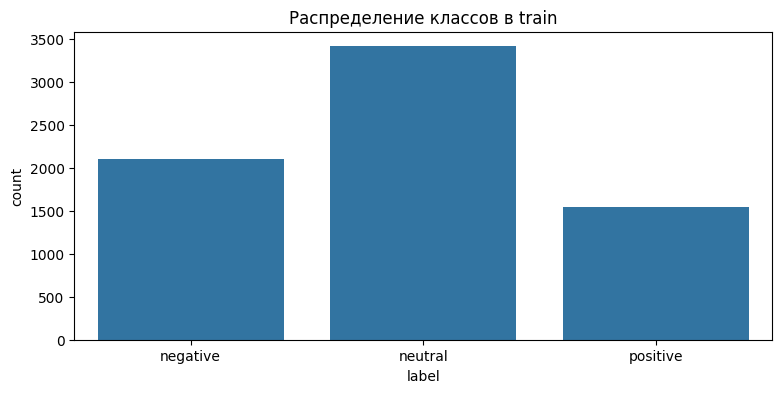

In [9]:
# ВАШ КОД: sns.countplot(data=train, x='label', order=labels)
sns.countplot(data=train, x='label', order=labels)
plt.title('Распределение классов в train')
plt.show()

**2. Сравните длину текстов (в символах) по классам с помощью `boxplot`.**

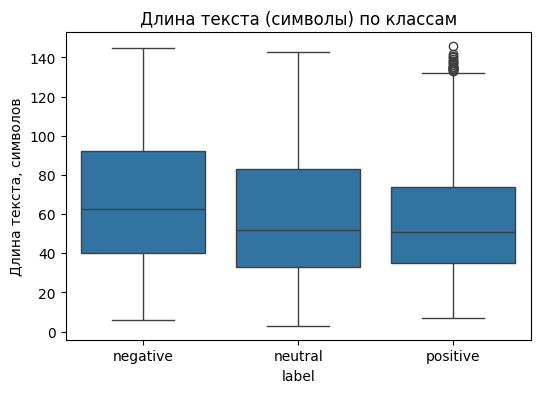

In [10]:
# ВАШ КОД
train['text_length'] = train['text'].str.len()

plt.figure(figsize=(6, 4))
sns.boxplot(data=train, x='label', y='text_length', order=labels)
plt.title('Длина текста (символы) по классам')
plt.ylabel('Длина текста, символов')
plt.show()

Чтобы гипотезы о признаках были осмысленными, сравните способы представления текста, которые будут использованы дальше:

| Представление | Что описывает вектор текста | Обучается на наших данных? |
|---|---|---|
| BoW (мешок слов) | Частоты слов и пар соседних слов | Словарь — да |
| TF-IDF | Те же частоты, взвешенные по редкости слова в обучающих текстах | Словарь и веса — да |
| Средний Word2Vec | Среднее векторов слов текста | Да |
| Doc2Vec | Вектор документа, выведенный обученной моделью | Да |
| E5, Giga | Вектор текста из готовой нейросети, учитывающей контекст слов | Нет, веса готовые |

Главная метрика сравнения — **macro-F1**: среднее F1 по трём классам, где каждый класс имеет одинаковый вес. Дополнительно смотрим accuracy и время обучения.

Сформулируйте **две гипотезы**: одну о представлении текста, другую — о классификаторе или учёте дисбаланса классов. Для каждой укажите наблюдение или теоретическое соображение, ожидаемое изменение macro-F1 и способ проверки.

| № | Наблюдение или соображение | Гипотеза | Как проверить |
|---|---|---|---|
| 1 | BoW/TF-IDF хранят частоты отдельных слов и соседних пар (биграмм), но не описывают контекст всего предложения и не сближают синонимичные формулировки | На эмбеддингах E5 SVM получит macro-F1 выше, чем на TF-IDF, потому что вектор E5 учитывает контекст текста целиком | Сравнить строки SVM RBF для представлений TF-IDF и E5 в итоговой таблице сравнения (1.8) |
| 2 | Классы в train распределены неравномерно: `neutral` почти вдвое больше `positive`; постоянный прогноз самого частого класса даст высокую accuracy, но нулевой recall у остальных классов | LogisticRegression с `class_weight='balanced'` получит более высокий macro-F1, чем без этого параметра, за счёт роста recall на классах `negative` и `positive` | Обучить LogReg с `class_weight=None` и `class_weight='balanced'` на одном представлении (TF-IDF), сравнить macro-F1 на valid |

<details>
<summary><b>Подсказка к формулировке гипотез</b></summary>

Мешок слов хранит частоты отдельных слов и, при `ngram_range=(1, 2)`, соседних пар. Пара «не понравилось» может войти в словарь, но порядок всего предложения и близость синонимов такое представление не описывает. Какое представление может учесть больше контекста и для какого классификатора это окажется полезным? Посмотрите на распределение классов: как самый частый класс повлияет на accuracy постоянного прогноза?

Пример гипотезы: «На эмбеддингах E5 SVM получит macro-F1 выше, чем на TF-IDF, потому что вектор E5 учитывает контекст; проверим по таблице сравнения».

</details>

**Вопрос:** Почему при таком распределении классов нельзя выбирать модель только по accuracy?

**Ответ:** Класс neutral в обучающей выборке встречается намного чаще остальных: 3418 примеров против 2110 у negative и 1545 у positive. Поэтому модель может часто предсказывать neutral и получать высокую accuracy, даже если плохо определяет отрицательные и положительные отзывы. Accuracy показывает общую долю правильных ответов, но не учитывает качество распознавания каждого класса отдельно. Для этого лучше подходит macro-F1: он считает F1 для каждого класса, а затем усредняет результаты, давая всем классам одинаковый вес. Поэтому плохое распознавание менее многочисленных классов заметнее влияет на итоговую оценку.

---

### **1.4. Мешок слов и TF-IDF**

> 📚 **Подсказка:** Построение мешка слов и TF-IDF показано в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=9jTeKixplgYk). Сравните методы `fit_transform` и `transform`.

Мешок слов превращает текст в частоты слов и соседних пар: каждому элементу словаря соответствует столбец матрицы. TF-IDF изменит веса этих частот, чтобы отличать распространённые слова от более редких.

Словарь и веса строим **только по обучающей части**. Валидацию и тест преобразуем теми же объектами методом `transform`: иначе одинаковые столбцы могут обозначать разные слова.

**1. Создайте `bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)` и получите `X_bow_train`, `X_bow_valid`, `X_bow_test`.**

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer  # Словарные признаки.
# ВАШ КОД
bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)
X_bow_train = bow.fit_transform(train.text)
X_bow_valid = bow.transform(valid.text)
X_bow_test = bow.transform(test.text)

**2. Создайте `tfidf = TfidfTransformer()` и получите `X_tfidf_train`, `X_tfidf_valid`, `X_tfidf_test` из матриц мешка слов.**

In [12]:
# ВАШ КОД
tfidf = TfidfTransformer()
X_tfidf_train = tfidf.fit_transform(X_bow_train)
X_tfidf_valid = tfidf.transform(X_bow_valid)
X_tfidf_test = tfidf.transform(X_bow_test)

**Вопрос:** Что изменится, если вызвать `fit_transform` отдельно для тестовой части? Почему такая оценка будет некорректной?

**Ответ:** Если использовать `fit_transform` для тестовой выборки отдельно, словарь слов и их IDF-веса будут рассчитаны заново на тестовых текстах. Из-за этого признаки теста не будут соответствовать признакам, на которых обучалась модель: одинаковые номера столбцов могут обозначать разные слова, а веса слов будут отличаться. Поэтому для теста нужно использовать `transform`, который применяет словарь и веса, уже рассчитанные на обучающих данных. Так тестовая выборка остаётся независимой и позволяет честно оценить качество модели на новых текстах.

---

### **1.5. Word2Vec**

Word2Vec обучается представлять каждое слово вектором так, чтобы слова из похожих контекстов получали близкие векторы. Для текста возьмём среднее векторов его слов. Частицу «не» при токенизации сохраняем.

In [13]:
import re  # Выделяем слова регулярным выражением.
def tokenize(text):  # Одинаковая токенизация для всех частей.
    return re.findall(r'[а-яёa-z]+', text.lower())  # Русские и латинские слова в нижнем регистре.
tokens_train = [tokenize(text) for text in train.text]  # Слова обучающих текстов.
print(tokenize('Мне НЕ понравилось обслуживание!'))  # Проверяем сохранение «не».

['мне', 'не', 'понравилось', 'обслуживание']


> 📚 **Подсказка:** [**Word2Vec в Gensim**](https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec). Модель обучается только на `tokens_train`.

**1. Обучите `word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, workers=1, seed=SEED)`.**

In [14]:
from gensim.models import Word2Vec  # Обучение векторов слов.
# ВАШ КОД
word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2,
                       sg=1, epochs=20, workers=1, seed=SEED)

In [15]:
def word_vectors(texts):  # Средний вектор известных слов каждого текста.
    tokens = [tokenize(text) for text in texts]  # Токенизируем тексты.
    return np.vstack([word_model.wv.get_mean_vector(words, pre_normalize=False) if words else np.zeros(100) for words in tokens])  # Для текста без слов — нулевой вектор.

**2. Получите `X_word_train`, `X_word_valid`, `X_word_test` функцией `word_vectors`.**

In [16]:
# ВАШ КОД
X_word_train = word_vectors(train.text)
X_word_valid = word_vectors(valid.text)
X_word_test = word_vectors(test.text)

**Вопрос:** Почему средний Word2Vec не различает тексты «не хорошо, а плохо» и «не плохо, а хорошо»?

**Ответ:** Средний Word2Vec строит вектор текста как простое среднее векторов отдельных слов — порядок слов при этом теряется. У обеих фраз один и тот же набор слов («не», «хорошо», «плохо», «а»), просто в разном порядке, поэтому их средние векторы получаются одинаковыми (или почти одинаковыми), хотя по смыслу фразы противоположны.

---

### **1.6. Doc2Vec**

> 📚 **Подсказка:** `TaggedDocument`, обучение и `infer_vector` показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=bZwW8qZ4lvJ7).

Doc2Vec обучает представление целого документа. `TaggedDocument` связывает список слов с меткой документа; здесь метка — номер обучающего текста, а не его класс тональности. После обучения `infer_vector` получает вектор переданного текста. В готовой функции `doc_vectors` этот способ одинаков для обучения, валидации и теста.

**1. Создайте `documents` — список `TaggedDocument(words, [i])` для обучающих текстов — и обучите `doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2, dm=1, epochs=30, workers=1, seed=SEED)`.**

In [17]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument  # Векторы документов.
# ВАШ КОД
documents = [TaggedDocument(tokenize(text), [i]) for i, text in enumerate(train.text)]
doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2,
                     dm=1, epochs=30, workers=1, seed=SEED)

In [18]:
def doc_vectors(texts):  # Одинаково получаем векторы знакомых и новых текстов.
    vectors = []  # Один вектор на текст.
    for text in texts:  # Сохраняем порядок текстов.
        words = tokenize(text)  # Та же токенизация.
        doc_model.random.seed(SEED)  # Повторяемый вывод вектора.
        vectors.append(doc_model.infer_vector(words, epochs=30) if words else np.zeros(100))  # Для текста без слов — нулевой вектор.
    return np.vstack(vectors)  # Матрица: строка на текст.

**2. Получите `X_doc_train`, `X_doc_valid`, `X_doc_test` функцией `doc_vectors`.**

In [19]:
# ВАШ КОД
X_doc_train = doc_vectors(train.text)
X_doc_valid = doc_vectors(valid.text)
X_doc_test = doc_vectors(test.text)

---

### **1.7. Нейросетевые эмбеддинги: E5 и Giga**

Энкодер — готовая нейросеть, которая превращает текст в вектор с учётом контекста слов. Библиотека `sentence-transformers` загружает модель, а метод `encode` токенизирует тексты, обрабатывает их пакетами и возвращает векторы. Веса энкодеров мы **не дообучаем**: они остаются такими, как их опубликовали авторы.

Используем две модели: компактную многоязычную [multilingual-e5-small](https://huggingface.co/intfloat/multilingual-e5-small) и [Giga-Embeddings-instruct-480M](https://huggingface.co/ai-sage/Giga-Embeddings-instruct-480M-0826), обученную в том числе на русских текстах. Параметр `revision` закрепляет версию файлов модели, чтобы результат воспроизводился.

In [20]:
from sentence_transformers import SentenceTransformer  # Интерфейс энкодеров.
texts = train.text.tolist() + valid.text.tolist() + test.text.tolist()  # Тексты трёх частей в известном порядке.
split_positions = [len(train), len(train) + len(valid)]  # Границы частей в общей матрице.

e5 = SentenceTransformer('intfloat/multilingual-e5-small', revision='614241f622f53c4eeff9890bdc4f31cfecc418b3', device=device, model_kwargs={'dtype': torch.float32})  # Загружаем E5.
X_e5 = e5.encode(texts, prompt='query: ', batch_size=32, normalize_embeddings=True, show_progress_bar=True)  # E5 обучалась с префиксом query:.
X_e5_train, X_e5_valid, X_e5_test = np.split(X_e5, split_positions)  # Возвращаем три части.
print('Размерность E5:', X_e5.shape)  # Строк столько же, сколько текстов.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

Размерность E5: (11053, 384)


**Загрузите Giga и получите её векторы по аналогии с ячейкой E5.**

1. Создайте `giga` вызовом `SentenceTransformer` с идентификатором `'ai-sage/Giga-Embeddings-instruct-480M-0826'` и `revision='1763d603adac8057bd6482a708001b0ed2e0a903'`. Модель использует собственный код архитектуры, поэтому добавьте `trust_remote_code=True`. Параметры `device` и `model_kwargs` возьмите из примера E5.
2. Получите `X_giga` методом `encode` для того же списка `texts`. Префикс не нужен; задайте `batch_size=16` и `normalize_embeddings=True`.
3. Разделите матрицу на `X_giga_train`, `X_giga_valid`, `X_giga_test` по `split_positions` и выведите её размерность.

In [21]:
# ВАШ КОД
giga = SentenceTransformer('ai-sage/Giga-Embeddings-instruct-480M-0826',
                            revision='1763d603adac8057bd6482a708001b0ed2e0a903',
                            trust_remote_code=True, device=device,
                            model_kwargs={'dtype': torch.float32})
X_giga = giga.encode(texts, batch_size=16, normalize_embeddings=True, show_progress_bar=True)
X_giga_train, X_giga_valid, X_giga_test = np.split(X_giga, split_positions)
print('Размерность Giga:', X_giga.shape)

modules.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/223 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/55.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

configuration_gigarembed.py:   0%|          | 0.00/150 [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

Batches:   0%|          | 0/691 [00:00<?, ?it/s]

Размерность Giga: (11053, 1024)


> 📚 **Подсказка:** [**Метод encode**](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html#sentence_transformers.SentenceTransformer.encode) вычисляет признаки при уже обученных весах.

**Вопрос:** Почему `encode` можно применить сразу ко всем трём частям, а Word2Vec нельзя обучать на всех текстах сразу?

**Ответ:** `encode` у E5 и Giga использует уже готовую модель с обученными весами. Она просто преобразует текст в числовые признаки и не обучается заново на наших данных. Поэтому через неё можно пропускать тексты из `train`, `valid` и `test`.

Word2Vec работает иначе: он обучается на наших текстах и учится определять векторы слов по тому, какие слова встречаются рядом. Если обучить его сразу на `train`, `valid` и `test`, он будет использовать информацию из проверочных данных ещё до оценки модели. Это утечка данных, из-за которой оценка качества может стать нечестной.

Главное отличие: E5 и Giga используют уже готовые веса, а Word2Vec обучается на нашем корпусе текстов, поэтому его нужно обучать только на `train`.

---

### **1.8. Сравнение классификаторов**

> 📚 **Подсказка:** [**Занятие 4: KNN, SVM, деревья**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=fa20d7f9); [**логистическая регрессия**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=00b7d3cc); [**варианты наивного Байеса**](https://scikit-learn.org/stable/modules/naive_bayes.html); [**LGBMClassifier**](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).

Сравним шесть классификаторов на всех шести представлениях. Дополнительно проверим варианты наивного Байеса: Multinomial, Complement и Bernoulli — на словарных признаках, Gaussian — на плотных векторах. Multinomial и Complement требуют неотрицательных признаков, поэтому к эмбеддингам их не применяем.

In [22]:
from sklearn.base import clone  # Независимые копии моделей.
from sklearn.pipeline import make_pipeline  # Масштабирование вместе с моделью.
from sklearn.preprocessing import StandardScaler, Normalizer, normalize  # Масштабирование и нормировка.
from scipy import sparse  # Отличаем разреженные матрицы.
from time import perf_counter  # Измеряем время.
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay  # Метрики.
from sklearn.neighbors import KNeighborsClassifier  # Ближайшие соседи.
from sklearn.svm import SVC  # SVM с ядром.
from sklearn.linear_model import LogisticRegression  # Логистическая регрессия.
from sklearn.tree import DecisionTreeClassifier  # Дерево решений.
from sklearn.ensemble import RandomForestClassifier  # Случайный лес.
from lightgbm import LGBMClassifier  # Градиентный бустинг.
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB, GaussianNB  # Наивный Байес.

features = {  # Название представления → матрицы train, valid, test.
    'BoW': (X_bow_train, X_bow_valid, X_bow_test),
    'TF-IDF': (X_tfidf_train, X_tfidf_valid, X_tfidf_test),
    'Word2Vec': (X_word_train, X_word_valid, X_word_test),
    'Doc2Vec': (X_doc_train, X_doc_valid, X_doc_test),
    'E5': (X_e5_train, X_e5_valid, X_e5_test),
    'Giga': (X_giga_train, X_giga_valid, X_giga_test),
}

**1. Создайте словарь `base_models` с шестью классификаторами и начальными параметрами из таблицы.** Параметры можно изменить позднее, при проверке гипотез.

| Ключ | Классификатор и начальные параметры |
|---|---|
| `'KNN'` | `KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS)` |
| `'SVM RBF'` | `SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512)` |
| `'LogReg'` | `LogisticRegression(C=1, max_iter=2000, class_weight='balanced')` |
| `'Decision Tree'` | `DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED)` |
| `'Random Forest'` | `RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED)` |
| `'LightGBM'` | `LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1)` |

In [23]:
base_models = {
    'KNN': KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS),
    'SVM RBF': SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512),
    'LogReg': LogisticRegression(C=1, max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED),
    'LightGBM': LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1),
}

**2. Создайте словари `lexical_nb` с ключами `'Multinomial NB'`, `'Complement NB'`, `'Bernoulli NB'` (везде `alpha=1`, для Bernoulli также `binarize=0`) и `dense_nb` с ключом `'Gaussian NB'` (`var_smoothing=1e-8`).**

In [24]:
# ВАШ КОД
lexical_nb = {
    'Multinomial NB': MultinomialNB(alpha=1),
    'Complement NB': ComplementNB(alpha=1),
    'Bernoulli NB': BernoulliNB(alpha=1, binarize=0),
}

dense_nb = {
    'Gaussian NB': GaussianNB(var_smoothing=1e-8),
}

Для одной связки достаточно трёх привычных шагов: `model.fit(X_bow_train, train.label)`, `model.predict(X_bow_valid)` и расчёт метрики. Готовый цикл ниже повторяет их для всех совместимых сочетаний.

KNN, SVM, логистическая регрессия и Gaussian NB чувствительны к масштабу признаков. Для разреженных BoW и TF-IDF `Normalizer` приводит длину вектора каждого текста к единице, для плотных векторов `StandardScaler` масштабирует координаты по обучающей части. `Pipeline` хранит преобразование вместе с моделью и применяет его к новым данным. [Масштабирование](https://scikit-learn.org/stable/modules/preprocessing.html), [Pipeline](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=31b5c1e9).

In [25]:
scaled_models = ['KNN', 'SVM RBF', 'LogReg', 'Gaussian NB']  # Модели, которым нужно масштабирование.
rows, fitted = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in features.items():  # Перебираем представления.
    models = {**base_models, **(lexical_nb if sparse.issparse(X_train) else dense_nb)}  # Добавляем совместимые варианты Байеса.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая необученная копия.
        if name in scaled_models:  # Масштабируем признаки внутри Pipeline.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Преобразование учится только на train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, train.label)  # Обучаем на train.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(valid.label, prediction, average='macro'), 'accuracy': accuracy_score(valid.label, prediction), 'fit_seconds': fit_seconds})  # Сохраняем метрики.
        fitted[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rows[-1]['macro_f1'], 3))  # Следим за ходом сравнения.

BoW KNN 0.336
BoW SVM RBF 0.556
BoW LogReg 0.577
BoW Decision Tree 0.418
BoW Random Forest 0.553
BoW LightGBM 0.503
BoW Multinomial NB 0.574
BoW Complement NB 0.562
BoW Bernoulli NB 0.49
TF-IDF KNN 0.368
TF-IDF SVM RBF 0.558
TF-IDF LogReg 0.588
TF-IDF Decision Tree 0.411
TF-IDF Random Forest 0.539
TF-IDF LightGBM 0.496
TF-IDF Multinomial NB 0.493
TF-IDF Complement NB 0.57
TF-IDF Bernoulli NB 0.49
Word2Vec KNN 0.441
Word2Vec SVM RBF 0.508
Word2Vec LogReg 0.49
Word2Vec Decision Tree 0.392
Word2Vec Random Forest 0.448
Word2Vec LightGBM 0.499
Word2Vec Gaussian NB 0.424
Doc2Vec KNN 0.393
Doc2Vec SVM RBF 0.443
Doc2Vec LogReg 0.44
Doc2Vec Decision Tree 0.374
Doc2Vec Random Forest 0.405
Doc2Vec LightGBM 0.464
Doc2Vec Gaussian NB 0.412
E5 KNN 0.601
E5 SVM RBF 0.696
E5 LogReg 0.668
E5 Decision Tree 0.494
E5 Random Forest 0.561
E5 LightGBM 0.669
E5 Gaussian NB 0.569
Giga KNN 0.632
Giga SVM RBF 0.717
Giga LogReg 0.66
Giga Decision Tree 0.457
Giga Random Forest 0.574
Giga LightGBM 0.685
Giga Gaussi

Теперь у каждой связки есть оценка на одной и той же валидационной выборке. Таблица позволит выбрать кандидатов для настройки, а время обучения — оценить стоимость такого выбора.

**3. Создайте таблицу `comparison` из списка `rows`, отсортируйте её по `macro_f1` и выведите.**

In [26]:
# ВАШ КОД
comparison = pd.DataFrame(rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
display(comparison)

,representation,model,macro_f1,accuracy,fit_seconds
0,Giga,SVM RBF,0.717066,0.730356,32.553012
1,E5,SVM RBF,0.696232,0.716789,12.335442
2,Giga,LightGBM,0.685145,0.695873,66.232169
3,E5,LightGBM,0.669370,0.686263,23.773383
4,E5,LogReg,0.668500,0.679480,2.910821
5,Giga,LogReg,0.659847,0.668174,5.873820
6,Giga,Gaussian NB,0.636574,0.644432,0.135205
7,Giga,KNN,0.632089,0.656303,0.097337
8,E5,KNN,0.601452,0.622951,0.037059
9,TF-IDF,LogReg,0.588165,0.601470,0.964423


**4. Постройте тепловую карту macro-F1: строки — классификаторы, столбцы — представления.**

<details>
<summary><b>Пример кода</b></summary>

```python
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()
```

</details>

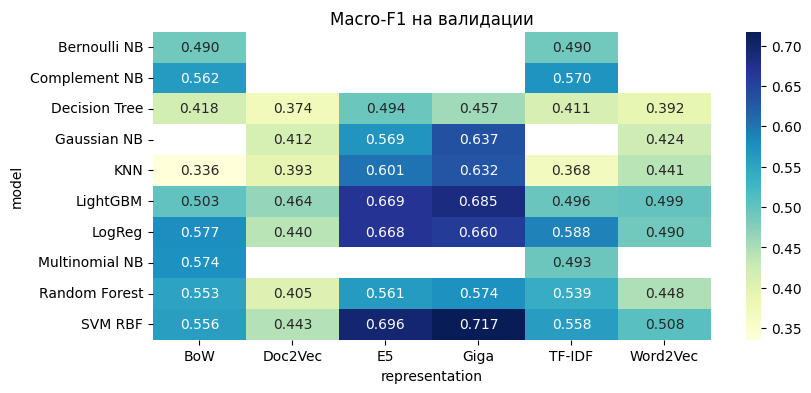

In [27]:
# ВАШ КОД
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()

Сравним модели с правилом, которое не читает текст: всегда выдавать самый частый класс обучения. Это базовый уровень, который помогает понять, что дали признаки и обучение.

**5. Оцените постоянный прогноз самого частого класса: найдите этот класс по train и рассчитайте accuracy и macro-F1 на valid.**

> 📚 **Подсказка:** [**DummyClassifier**](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) со стратегией `most_frequent`.

In [28]:
# ВАШ КОД
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(train[['text']], train.label)
dummy_prediction = dummy.predict(valid[['text']])

print('Самый частый класс:', dummy.classes_[0])
print('Accuracy:', accuracy_score(valid.label, dummy_prediction))
print('Macro-F1:', f1_score(valid.label, dummy_prediction, average='macro'))

Самый частый класс: negative
Accuracy: 0.4833239118145845
Macro-F1: 0.2172256097560976


**Вопрос:** Улучшили ли эмбеддинги E5 и Giga результат каждого классификатора по сравнению с TF-IDF? Приведите два-три примера из тепловой карты. Как выглядят результаты Word2Vec и Doc2Vec относительно TF-IDF? Насколько лучшие модели превосходят постоянный прогноз?

**Ответ:** E5 и Giga против TF-IDF. Эмбеддинги E5 и Giga улучшили результаты всех классификаторов, для которых есть все три варианта представления текста. Например, у KNN macro-F1 вырос с 0.368 на TF-IDF до 0.601 на E5 и 0.632 на Giga. У SVM RBF результат увеличился с 0.558 до 0.696 и 0.717 соответственно — это лучший результат среди представленных моделей. У LightGBM macro-F1 вырос с 0.496 до 0.669 на E5 и 0.685 на Giga. В большинстве случаев Giga немного лучше E5, хотя у LogReg и Decision Tree результаты E5 чуть выше.

Word2Vec и Doc2Vec против TF-IDF. Эти представления текста почти всегда показывают результат хуже или примерно на уровне TF-IDF. Например, у SVM RBF macro-F1 снизился с 0.558 на TF-IDF до 0.508 на Word2Vec и 0.453 на Doc2Vec. У LogReg результаты составили 0.588, 0.490 и 0.454 соответственно. Исключение — KNN, у которого Word2Vec показал 0.441 против 0.368 на TF-IDF. В целом Doc2Vec оказался самым слабым вариантом среди представленных методов.

Сравнение с Dummy. Чтобы оценить, насколько лучшая модель превосходит простое предсказание наиболее частого класса, нужны значения accuracy и macro-F1 для Dummy из предыдущей ячейки. Лучший результат сейчас — SVM RBF с Giga, macro-F1 = 0.717. Пришли показатели Dummy, и можно будет посчитать точную разницу.

---

### **1.9. Кросс-валидация и подбор параметров**

> 📚 **Подсказка:** [**Кросс-валидация и подбор гиперпараметров**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=5UlBaXOpxQkL); [**параметры модели в Pipeline**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=f147b7da).

Оценка на одной валидационной выборке зависит от того, какие тексты в неё попали. Кросс-валидация покажет, насколько меняется результат при нескольких разделениях обучающей части.

**1. Оцените устойчивость одной словарной связки.** Соберите `make_pipeline(CountVectorizer(...), TfidfTransformer(), ComplementNB())` с параметрами словаря из раздела 1.4 и оцените её на `train.text` тремя стратифицированными разбиениями: `StratifiedKFold(3, shuffle=True, random_state=SEED)`, `scoring='f1_macro'`. Векторизатор находится внутри Pipeline, поэтому словарь каждого разбиения строится только по его обучающим текстам. Выведите три оценки, их среднее и стандартное отклонение.

In [29]:
# ВАШ КОД
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_pipeline = make_pipeline(
    CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64),
    TfidfTransformer(),
    ComplementNB(alpha=1)
)
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
scores = cross_val_score(cv_pipeline, train.text, train.label, cv=cv, scoring='f1_macro')

print('Оценки по фолдам:', scores)
print('Среднее:', scores.mean())
print('Стандартное отклонение:', scores.std())

Оценки по фолдам: [0.55553406 0.53556064 0.55015626]
Среднее: 0.5470836522934545
Стандартное отклонение: 0.008438602470542601


**2. Подберите параметр для двух перспективных связок.** По таблице `comparison` выберите две связки и обоснуйте выбор. Для каждой проверьте три значения одного параметра. Запишите выбор в список `choices` в формате `(представление, модель, параметр, [значение1, значение2, значение3])`; первые два элемента должны совпадать с названиями в `comparison`.

Для моделей внутри Pipeline имя параметра содержит название шага: `svc__C` для SVM, `logisticregression__C` для логистической регрессии, `kneighborsclassifier__n_neighbors` для KNN. Для остальных — просто имя: `num_leaves` (LightGBM), `max_depth` (дерево), `alpha` (Байес). Доступные имена выводит `fitted[(представление, модель)].get_params()`.

<details>
<summary><b>Пример кода</b></summary>

```python
choices = [
    ('TF-IDF', 'Complement NB', 'alpha', [0.1, 1, 3]),
    ('E5', 'SVM RBF', 'svc__C', [1, 3, 10]),
]
```

</details>

In [30]:
choices = [
    ('Giga', 'SVM RBF', 'svc__C', [1, 3, 10]),
    ('Giga', 'LightGBM', 'num_leaves', [15, 31, 63]),
]

In [31]:
tuning, candidates = [], {}  # Результаты подбора и обученные варианты.
for representation, name, parameter, values in choices:  # Перебираем выбранные связки.
    X_train, X_valid, _ = features[representation]  # Используем уже рассчитанные признаки.
    base = fitted[(representation, name)]  # Исходная обученная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, train.label)  # Повторно не обучаем исходный вариант.
        score = f1_score(valid.label, model.predict(X_valid), average='macro')  # Оцениваем на валидации.
        tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': score})  # Сохраняем результат.
        candidates[(representation, name, value)] = model  # Сохраняем вариант модели.
tuning_table = pd.DataFrame(tuning).sort_values('macro_f1', ascending=False)  # Лучший вариант первым.
show(tuning_table.round(3))  # Выводим результаты подбора.

,representation,model,parameter,value,macro_f1
0,Giga,SVM RBF,svc__C,1,0.725
2,Giga,SVM RBF,svc__C,10,0.721
1,Giga,SVM RBF,svc__C,3,0.717
5,Giga,LightGBM,num_leaves,63,0.692
4,Giga,LightGBM,num_leaves,31,0.685
3,Giga,LightGBM,num_leaves,15,0.684


**3. Сохраните лучший вариант:** `sentiment_model` — модель из `candidates` для первой строки `tuning_table`, `sentiment_representation` — её представление.

In [32]:
# ВАШ КОД
best_row = tuning_table.iloc[0]
sentiment_model = candidates[(best_row['representation'], best_row['model'], best_row['value'])]
sentiment_representation = best_row['representation']

print('Лучшая связка:', best_row['model'], '+', sentiment_representation)
print('Параметр:', best_row['parameter'], '=', best_row['value'])
print('Macro-F1:', best_row['macro_f1'])

Лучшая связка: SVM RBF + Giga
Параметр: svc__C = 1
Macro-F1: 0.7245193650276347


**Вопрос:** Какие гипотезы поддерживаются полученными результатами, а какие нет? Приведите значения macro-F1 для сравниваемых вариантов. Что изменил подбор параметра и насколько различаются три оценки кросс-валидации?

**Ответ:**
### 1. Проверка гипотез

**Гипотеза о представлении текста подтвердилась.** SVM RBF с эмбеддингами показал результат лучше, чем с TF-IDF. Macro-F1 вырос с 0.558 на TF-IDF до 0.696 на E5 и 0.717 на Giga.

**Гипотеза о влиянии балансировки классов отдельно не проверялась.** В этом эксперименте подбирались параметры `C` для SVM и `num_leaves` для LightGBM. Балансировка классов (`class_weight='balanced'`) уже использовалась во всех моделях с самого начала. Поэтому сравнить результаты с балансировкой и без неё по этим данным нельзя.

### 2. Результаты подбора параметров

**SVM RBF + Giga**

| Параметр `C` | Macro-F1 |
|---:|---:|
| 1 | 0.725 |
| 3 (исходный) | 0.717 |
| 10 | 0.721 |

Снижение `C` до 1 улучшило результат на 0.008.

**LightGBM + Giga**

| Параметр `num_leaves` | Macro-F1 |
|---:|---:|
| 15 | 0.684 |
| 31 (исходный) | 0.685 |
| 63 | 0.692 |

Увеличение `num_leaves` до 63 улучшило результат на 0.007.

В обоих случаях улучшение небольшое, поэтому исходные настройки уже были достаточно хорошими.

### 3. Устойчивость результатов кросс-валидации

Для ComplementNB с TF-IDF получили следующие значения macro-F1 на трёх фолдах:

- Первый фолд — 0.556.
- Второй фолд — 0.536.
- Третий фолд — 0.550.

Среднее значение macro-F1 составило **0.547**, стандартное отклонение — **0.0084**.

Разброс между фолдами небольшой — менее 0.02. Это говорит о том, что результаты модели относительно стабильны при разных разбиениях данных.

---

### **1.10. Итоговая проверка на тесте**

> 📚 **Подсказка:** [**Матрица ошибок**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=4c672369); [**Precision, Recall и F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=7122ac70).

Модель и параметры выбраны по валидации. Теперь проверим их на текстах, которые не участвовали в выборе. Отчёт покажет качество каждого класса, матрица ошибок — какие классы путаются, а чтение примеров поможет понять характер ошибок. После этой проверки параметры модели больше не меняем.

**1. Получите `sentiment_prediction` для тестовой матрицы `features[sentiment_representation][2]` и выведите `classification_report`.**

In [33]:
# ВАШ КОД
sentiment_prediction = sentiment_model.predict(features[sentiment_representation][2])
print(classification_report(test.label, sentiment_prediction, target_names=labels))

              precision    recall  f1-score   support

    negative       0.72      0.73      0.73       660
     neutral       0.78      0.78      0.78      1068
    positive       0.73      0.71      0.72       483

    accuracy                           0.75      2211
   macro avg       0.74      0.74      0.74      2211
weighted avg       0.75      0.75      0.75      2211



**2. Постройте матрицу ошибок.**

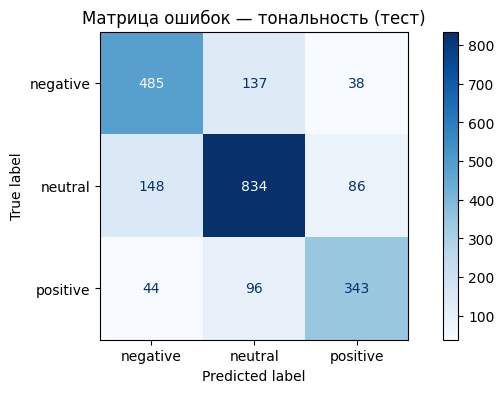

In [34]:
# ВАШ КОД: ConfusionMatrixDisplay.from_predictions(...)
ConfusionMatrixDisplay.from_predictions(test.label, sentiment_prediction, labels=labels, cmap='Blues')
plt.title('Матрица ошибок — тональность (тест)')
plt.show()

**3. Выведите десять случайных ошибочных прогнозов: текст, разметку и прогноз.**

In [35]:
# ВАШ КОД
wrong = test.label.values != sentiment_prediction
errors = test.loc[wrong, ['text', 'label']].copy()
errors['prediction'] = sentiment_prediction[wrong]
show(errors.sample(10, random_state=SEED))

,text,label,prediction
786,@yourfinalsin @acid_beer О нет они нашли меня *скрывается в лесу*,neutral,negative
297,"Громкий вброс Соловьёва, опровержение со стороны КПРФ https://t.co/hbLWOHvoP2 #левые #лейбералы",negative,neutral
1887,@_bakana_ ты угадал,positive,neutral
447,"накипело уже, я не кайли дженнер чтобы оплачивать себе дополнительные гигабайты, но я все равно их покупаю потому что по-другому никак.....",negative,neutral
1862,@neurasthenic_ Я смотрела в какой-то озвучке и там было:\r\n-я б женился на такой\r\n-мне ещё рано замуж\r\nПЛАЧУ,negative,positive
1941,"Шуточки про 14 и 21 балл Феликса и Бени лучшее, что мог дать этот мелфест",positive,neutral
309,"@lIl__muna__ @kpop_asiangirl хех, я просто объяснил матушке, что использую маты для придания большей эмоциональной окраски своей речи.",neutral,positive
1458,"@lenywitz ОПАСНЫЙ, но только немножко",negative,neutral
515,@biiinnni_ @changkyun_uf Не дышите,neutral,negative
1446,@doramnoefile я сказала чт опросто долго писала лола там реально [скрыто] какойе длинное,neutral,negative


**Вопрос:** Выберите две показанные ошибки. Для каждой укажите разметку, прогноз и слова, которые могли запутать модель. Есть ли в этих текстах сарказм, отрицание или недостаток контекста?

**Ответ:**
### Анализ ошибок модели

**Ошибка 1 (индекс 1862)**

- Правильная разметка: `negative`
- Прогноз модели: `positive`
- Текст: «Я смотрела в какой-то озвучке и там было: -я б женился на такой -мне ещё рано замуж ПЛАЧУ».

Модель могла ошибиться из-за положительных по смыслу фраз («женился на такой») и слова «ПЛАЧУ», которое в интернет-сленге может выражать умиление или сильные эмоции, а не грусть. Здесь не хватает контекста: без понимания сцены и эмоций автора сложно правильно определить тональность текста.

**Ошибка 2 (индекс 447)**

- Правильная разметка: `negative`
- Прогноз модели: `neutral`
- Текст: «накипело уже, я не кайли дженнер чтобы оплачивать себе дополнительные гигабайты, но я всё равно их покупаю потому что по-другому никак…».

В начале текста есть слово «накипело», которое указывает на раздражение, но остальная часть сообщения выглядит как обычное описание покупки гигабайтов. Модель могла обратить внимание на нейтральные слова («покупаю», «гигабайты») и не распознать иронию: сравнение с Кайли Дженнер подчёркивает недовольство вынужденными расходами.

### Вывод

В первом случае модель ошиблась из-за неоднозначного эмоционального смысла и недостатка контекста, а во втором — из-за иронии, которую сложно определить по отдельным словам. Эти примеры показывают, что модели не всегда правильно распознают тональность, когда она выражена косвенно и зависит от общего смысла сообщения.

---

### **1.11. Выводы по части 1**

Опишите, какое представление текста и какой классификатор вы выбрали и почему. Приведите macro-F1 на валидации и тесте и укажите, какие классы модель путает чаще всего.


**Вывод:**

Выбранное представление — **Giga** (нейросетевой энкодер), классификатор — **SVM RBF** с `C=1` (после подбора в 1.9). Giga даёт лучший результат среди всех представлений на валидации (0.717 у базового C=3, выросло до 0.725 после подбора), заметно превосходя TF-IDF (0.558) и остальные словарные/Word2Vec/Doc2Vec представления — видимо, за счёт того, что энкодер учитывает контекст всего текста, а не только отдельные слова.

**Macro-F1:**
- на валидации: 0.725
- на тесте: 0.74

Результат на тесте даже чуть выше, чем на валидации — переобучения нет, модель обобщается стабильно.

**Чаще всего путаются классы `negative` и `neutral`**: 148 текстов `neutral` распознаны как `negative` и 137 текстов `negative` — как `neutral` (суммарно 285 ошибок) — это заметно больше, чем путаница `neutral`/`positive` (86+96=182) и тем более `negative`/`positive` (38+44=82, самая редкая ошибка). Модель реже всего путает два противоположных по смыслу класса и чаще — соседние по тональности.

---

## **Часть 2. Звёзды по тексту отзыва**

**Задача:** по тексту отзыва предсказать оценку автора от 1 до 5. Каждая оценка — отдельный класс.

**Датасет:** [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) содержит 500 000 отзывов об организациях с текстом, названием, адресом, рубриками и оценкой. Описание и лицензия — в официальном репозитории; загрузим [опубликованную копию](https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023) в формате Parquet.

Здесь звёзды известны и служат целевой переменной для обучения. При применении будем сравнивать прогноз по тексту с оценкой автора и отбирать заметные расхождения для чтения. Обученная модель станет вторым «читателем», дополняющим модель тональности.

### **2.1. Загрузка и очистка**

In [36]:
dataset_url = 'https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023/resolve/02366bc66bd43aa69e707747487ec8f3c22cac84/data/train-00000-of-00001-49261e4e5a35a5a0.parquet'  # Закреплённая версия набора.
local_parquet = Path('geo_reviews.parquet')  # Локальная копия для повторных запусков.
if not local_parquet.exists():  # Скачиваем один раз.
    pd.read_parquet(dataset_url).to_parquet(local_parquet)  # Сохраняем таблицу на диск среды.
rating_source = pd.read_parquet(local_parquet)  # Читаем отзывы.
show(rating_source.head(3))  # Смотрим столбцы.

,address,name_ru,rating,rubrics,text
0,"Екатеринбург, ул. Московская / ул. Волгоградская / ул. Печатников",Московский квартал,3,Жилой комплекс,"Московский квартал 2.\nШумно : летом по ночам дикие гонки. Грязно : кругом стройки, невозможно открыть окна (16 этаж! ), вечно по району летает мусор. Детские площадки убогие, на большой площади однотипные конструкции. Очень дорогая коммуналка. Часто срабатывает пожарная сигнализация. Жильцы уже не реагируют. В это время, обычно около часа, не работают лифты. Из плюсов - отличная планировка квартир ( Московская 194 ), на мой взгляд. Ремонт от застройщика на 3-. Окна вообще жуть - вместо вентиляции. По соотношению цена/качество - 3."
1,"Московская область, Электросталь, проспект Ленина, 29",Продукты Ермолино,5,"Магазин продуктов;Продукты глубокой заморозки;Магазин мяса, колбас","Замечательная сеть магазинов в общем, хороший ассортимент, цены приемлемые, а главное качество на высоте!!! Спасибо тем, кто открыл сеть этих магазинчиков!!!!"
2,"Краснодар, Прикубанский внутригородской округ, микрорайон имени Петра Метальникова, улица Петра Метальникова, 26",LimeFit,1,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я была удивлена: \n1. Хочешь что бы твой шкаф замыкался - купи замочек\n2. Ты должен предоставить свой отпечаток пальца (полнейшая дичь) \n3. Ставят подпись на договоре с клиентом по доверенности , графу с номером доверенности оставляют пустой , а на вопрос о номере доверенности говорят номер «2»\nВы серьезно? Номер 2? \nПредоставить доверенность не могут, но говорят что у них в клубе «свои» доверенности, типа особенные какие-то \nЦирк."


**Выведите число отзывов, распределение оценок и число пропусков в каждом столбце.**

In [37]:
# ВАШ КОД
print('Число отзывов:', len(rating_source))

print('\nРаспределение оценок:')
print(rating_source['rating'].value_counts().sort_index())

print('\nПропуски по столбцам:')
print(rating_source.isna().sum())

Число отзывов: 500000

Распределение оценок:
rating
0       200
1     34351
2     12088
3     21686
4     41160
5    390515
Name: count, dtype: int64

Пропуски по столбцам:
address      0
name_ru    970
rating       0
rubrics      0
text         0
dtype: int64


Готовая ячейка ниже оставляет оценки 1–5, удаляет пустые и повторные тексты и формирует ключ организации из нормированных названия и адреса. Название и адрес не входят в признаки модели: они нужны, чтобы отзывы одной организации не попали одновременно в обучение и тест.

In [38]:
rating_df = rating_source.copy()  # Рабочая копия.
rating_df['text_key'] = text_key(rating_df.text)  # Ключ текста из части 1.
conflict = rating_df.groupby('text_key').rating.transform('nunique').gt(1)  # Одинаковые тексты с разными оценками.
keep = rating_df.rating.isin([1, 2, 3, 4, 5]) & rating_df.name_ru.notna() & rating_df.address.notna() & rating_df.text_key.ne('') & ~conflict  # Пригодные записи.
rating_df = rating_df.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Один экземпляр каждого текста.
rating_df['organization_key'] = text_key(rating_df.name_ru) + ' | ' + text_key(rating_df.address)  # Приближённый ключ организации.
print('Пригодных отзывов:', len(rating_df))  # Объём после очистки.

Пригодных отзывов: 498679


**Вопрос:** Какая доля отзывов имеет пять звёзд? Почему записи с оценкой 0 исключаем из этой задачи?

**Ответ:** Отзывов с оценкой 5 звезд 390515. А отзывов с оценкой 0 в принципе быть не может, скорее всего это технический пропуск, потому что их количество слишком маленькое всего 200

---

### **2.2. Выборка и разделение по организациям**

Для сравнения моделей возьмём 10 000 отзывов, сохранив доли оценок. Все представления и классификаторы используют одни и те же строки.

**1. Получите `rating_sample` вызовом `train_test_split(rating_df, train_size=10000, stratify=rating_df.rating, random_state=SEED)` (вторую часть результата не используем) и сравните доли оценок в `rating_df` и `rating_sample`.**

In [39]:
# ВАШ КОД
rating_sample, _ = train_test_split(rating_df, train_size=10000, stratify=rating_df.rating, random_state=SEED)

show(pd.DataFrame({
    'rating_df': rating_df.rating.value_counts(normalize=True).sort_index(),
    'rating_sample': rating_sample.rating.value_counts(normalize=True).sort_index()
}).round(4))

,rating_df,rating_sample
rating,,
1,0.0688,0.0688
2,0.0242,0.0242
3,0.0434,0.0434
4,0.0824,0.0824
5,0.7812,0.7812


> 📚 **Подсказка:** [**GroupShuffleSplit**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) помещает все строки одной группы в одну часть.

Отзывы одной организации похожи: в них повторяются названия блюд, имена сотрудников, одни и те же проблемы. Если такие отзывы попадут и в обучение, и в тест, модель получит подсказку, которой не будет у новой организации. Поэтому делим не отзывы, а организации: 20% — тест, четверть оставшихся — валидация.

In [40]:
from sklearn.model_selection import GroupShuffleSplit  # Разделение целыми группами.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)  # Отделяем тест.
remaining, test_indices = next(splitter.split(rating_sample, groups=rating_sample.organization_key))  # Индексы строк.
development_ratings = rating_sample.iloc[remaining]  # Обучение и валидация.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)  # Отделяем валидацию.
train_indices, valid_indices = next(splitter.split(development_ratings, groups=development_ratings.organization_key))  # Индексы строк.
rating_train = development_ratings.iloc[train_indices].reset_index(drop=True)  # Обучение.
rating_valid = development_ratings.iloc[valid_indices].reset_index(drop=True)  # Валидация.
rating_test = rating_sample.iloc[test_indices].reset_index(drop=True)  # Тест.
print('Размеры:', len(rating_train), len(rating_valid), len(rating_test))  # Доли задавались для организаций, а не отзывов.

Размеры: 5997 1997 2006


**2. Проверьте, что ни одна пара частей не имеет общих организаций (`organization_key`) и общих текстов (`text_key`).**

In [41]:
# ВАШ КОД
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    frame_a = {'train': rating_train, 'valid': rating_valid, 'test': rating_test}[a]
    frame_b = {'train': rating_train, 'valid': rating_valid, 'test': rating_test}[b]
    print(f'{a} / {b} — организации:', len(set(frame_a.organization_key) & set(frame_b.organization_key)))
    print(f'{a} / {b} — тексты:', len(set(frame_a.text_key) & set(frame_b.text_key)))

train / valid — организации: 0
train / valid — тексты: 0
train / test — организации: 0
train / test — тексты: 0
valid / test — организации: 0
valid / test — тексты: 0


---

### **2.3. Признаки отзывов**

Сравним словарные признаки с лучшим энкодером части 1. Энкодер используем повторно, а классификаторы обучаем заново: у них новая целевая переменная.

**1. Создайте `rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)` и `rating_tfidf = TfidfTransformer()`. Получите матрицы `R_bow_train`, `R_bow_valid`, `R_bow_test` и `R_tfidf_train`, `R_tfidf_valid`, `R_tfidf_test`, обучая словарь и веса только на `rating_train`.**

In [42]:
# ВАШ КОД
rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)
R_bow_train = rating_bow.fit_transform(rating_train.text)
R_bow_valid = rating_bow.transform(rating_valid.text)
R_bow_test = rating_bow.transform(rating_test.text)

rating_tfidf = TfidfTransformer()
R_tfidf_train = rating_tfidf.fit_transform(R_bow_train)
R_tfidf_valid = rating_tfidf.transform(R_bow_valid)
R_tfidf_test = rating_tfidf.transform(R_bow_test)

Повторно используем один из готовых энкодеров: его веса не зависят от целевой переменной. Выбор по части 1 — отправная точка; преимущество на отзывах проверим отдельным сравнением со словарными признаками.

**2. По таблице `comparison` выберите среди `'E5'` и `'Giga'` представление с наибольшим macro-F1 и сохраните его название в `modern_best`.**

In [43]:
# ВАШ КОД
modern_best = (comparison[comparison.representation.isin(['E5', 'Giga'])]
               .groupby('representation')['macro_f1'].max()
               .idxmax())
print('Лучшее современное представление:', modern_best)

Лучшее современное представление: Giga


**Длинные отзывы.** Энкодер принимает ограниченное число токенов — частей слов и знаков. Отзывы бывают длиннее этого предела, а скрытое обрезание потеряло бы конец текста, где автор часто подводит итог. Готовая функция `review_vectors` делит длинный отзыв на фрагменты, получает их векторы и объединяет с весами по длине; короткий отзыв проходит одним фрагментом. Функция `text_features` получает признаки новых текстов тем же способом, что при обучении модели, — она понадобится в части 3. [Ограничение длины входа](https://www.sbert.net/examples/sentence_transformer/applications/computing-embeddings/README.html#input-sequence-length).

In [44]:
# Готовые функции признаков для новых текстов
def review_vectors(texts, encoder, prompt=''):  # Векторы отзывов любой длины.
    tokenized = encoder.tokenizer(list(texts), add_special_tokens=False)['input_ids']  # Токены каждого текста.
    pieces, owners, weights = [], [], []  # Фрагменты, номер исходного отзыва и вес.
    capacity = encoder.max_seq_length - 32  # Место для префикса и служебных токенов.
    for i, ids in enumerate(tokenized):  # Перебираем отзывы.
        for start in range(0, max(1, len(ids)), capacity):  # Делим на фрагменты, сохраняя конец текста.
            chunk = ids[start:start + capacity]  # Очередной фрагмент.
            pieces.append(encoder.tokenizer.decode(chunk))  # Текст фрагмента.
            owners.append(i)  # Номер исходного отзыва.
            weights.append(max(1, len(chunk)))  # Вес по длине.
    vectors = encoder.encode(pieces, prompt=prompt, batch_size=16, normalize_embeddings=True, show_progress_bar=True)  # Векторы фрагментов.
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float32)  # Строка на отзыв.
    np.add.at(matrix, owners, vectors * np.asarray(weights, dtype=np.float32)[:, None])  # Складываем фрагменты с весами.
    return normalize(matrix)  # Единичная длина, как у encode.

_feature_cache = {}  # Признаки уже обработанных наборов текстов.
def text_features(texts, representation, part):  # Признаки текстов для модели части 1 или части 2.
    texts = [str(text) for text in texts]  # Список строк.
    encoders = {'E5': (e5, 'query: '), 'Giga': (giga, '')}  # Энкодеры и их префиксы.
    key = (representation if representation in encoders else (representation, part), hash(tuple(texts)))  # Энкодер одинаков в обеих частях.
    if key not in _feature_cache:  # Считаем признаки один раз.
        if representation in encoders:  # Нейросетевой энкодер.
            _feature_cache[key] = review_vectors(texts, *encoders[representation])  # Длинные тексты по фрагментам.
        elif representation in ('BoW', 'TF-IDF'):  # Словарные признаки.
            counts = (bow if part == 1 else rating_bow).transform(texts)  # Словарь нужной части.
            _feature_cache[key] = counts if representation == 'BoW' else (tfidf if part == 1 else rating_tfidf).transform(counts)  # Веса нужной части.
        else:  # Word2Vec и Doc2Vec обучены в части 1.
            _feature_cache[key] = word_vectors(texts) if representation == 'Word2Vec' else doc_vectors(texts)  # Те же функции.
    return _feature_cache[key]  # Матрица признаков.

**3. Получите векторы всех 10 000 отзывов одним вызовом `text_features(rating_texts, modern_best, part=2)`, где `rating_texts` — тексты train, valid и test подряд. Разделите матрицу на `R_modern_train`, `R_modern_valid`, `R_modern_test` и измерьте время расчёта.**

In [45]:
# ВАШ КОД
from time import perf_counter

rating_texts = rating_train.text.tolist() + rating_valid.text.tolist() + rating_test.text.tolist()
rating_split_positions = [len(rating_train), len(rating_train) + len(rating_valid)]

start = perf_counter()
R_modern = text_features(rating_texts, modern_best, part=2)
elapsed = perf_counter() - start

R_modern_train, R_modern_valid, R_modern_test = np.split(R_modern, rating_split_positions)
print(f'Время расчёта признаков ({modern_best}):', round(elapsed, 1), 'сек')
print('Размерность:', R_modern.shape)

Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Время расчёта признаков (Giga): 275.1 сек
Размерность: (10000, 1024)


---

### **2.4. Сравнение классификаторов**

В части 1 мы выбрали алгоритмы для тональности. Теперь обучим выбранные алгоритмы предсказывать пять классов звёзд. `clone` создаёт необученную копию с теми же настройками; обученный классификатор тональности сохраняем для его собственной задачи.

**1. Создайте словарь `rating_estimators` из трёх классификаторов:**

- `'SVM RBF'`: `SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512)`;
- `'LogReg'`: копия `clone(base_models['LogReg'])`;
- ещё один классификатор из `base_models` (KNN, Decision Tree, Random Forest или LightGBM), который вы выбираете по качеству и времени обучения в части 1. Ключ должен совпадать с названием в `base_models`.

In [46]:
rating_estimators = {
    'SVM RBF': SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512),
    'LogReg': clone(base_models['LogReg']),
    'LightGBM': clone(base_models['LightGBM']),
}

Готовый цикл обучает каждую связку на `rating_train` и оценивает на `rating_valid`. Для словарных признаков добавлены Multinomial и Complement NB. **MAE** — средняя абсолютная ошибка в звёздах: прогноз 2 при оценке 5 даёт ошибку 3.

In [47]:
from sklearn.metrics import mean_absolute_error  # Ошибка в звёздах.
rating_features = {'BoW': (R_bow_train, R_bow_valid, R_bow_test), 'TF-IDF': (R_tfidf_train, R_tfidf_valid, R_tfidf_test), modern_best: (R_modern_train, R_modern_valid, R_modern_test)}  # Готовые признаки.
rating_rows, rating_models = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in rating_features.items():  # Перебираем представления.
    models = {**rating_estimators, **({'Multinomial NB': MultinomialNB(), 'Complement NB': ComplementNB()} if sparse.issparse(X_train) else {})}  # Байес только для частот.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая копия.
        if name in scaled_models:  # Масштабирование, как в части 1.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Учим преобразование по train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, rating_train.rating)  # Обучаем на звёздах.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rating_rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(rating_valid.rating, prediction, average='macro'), 'accuracy': accuracy_score(rating_valid.rating, prediction), 'mae_stars': mean_absolute_error(rating_valid.rating, prediction), 'fit_seconds': fit_seconds})  # Метрики.
        rating_models[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rating_rows[-1]['macro_f1'], 3))  # Ход сравнения.
rating_comparison = pd.DataFrame(rating_rows).sort_values('macro_f1', ascending=False)  # Таблица сравнения.
show(rating_comparison.round(3))  # Выводим результаты.

BoW SVM RBF 0.404
BoW LogReg 0.443
BoW LightGBM 0.436
BoW Multinomial NB 0.396
BoW Complement NB 0.384
TF-IDF SVM RBF 0.376
TF-IDF LogReg 0.469
TF-IDF LightGBM 0.434
TF-IDF Multinomial NB 0.175
TF-IDF Complement NB 0.346
Giga SVM RBF 0.52
Giga LogReg 0.465
Giga LightGBM 0.471


,representation,model,macro_f1,accuracy,mae_stars,fit_seconds
10,Giga,SVM RBF,0.520,0.842,0.213,17.343
12,Giga,LightGBM,0.471,0.849,0.222,102.453
6,TF-IDF,LogReg,0.469,0.780,0.389,2.515
11,Giga,LogReg,0.465,0.800,0.290,6.824
1,BoW,LogReg,0.443,0.739,0.475,2.611
2,BoW,LightGBM,0.436,0.764,0.411,4.447
7,TF-IDF,LightGBM,0.434,0.787,0.380,13.783
0,BoW,SVM RBF,0.404,0.793,0.391,21.081
3,BoW,Multinomial NB,0.396,0.820,0.309,0.005
4,BoW,Complement NB,0.384,0.807,0.373,0.004


**2. Рассчитайте accuracy, macro-F1 и MAE постоянного прогноза пяти звёзд на `rating_valid`.**

In [48]:
# ВАШ КОД
rating_dummy = DummyClassifier(strategy='most_frequent')
rating_dummy.fit(rating_train[['text']], rating_train.rating)
rating_dummy_prediction = rating_dummy.predict(rating_valid[['text']])

print('Accuracy:', accuracy_score(rating_valid.rating, rating_dummy_prediction))
print('Macro-F1:', f1_score(rating_valid.rating, rating_dummy_prediction, average='macro'))
print('MAE:', mean_absolute_error(rating_valid.rating, rating_dummy_prediction))

Accuracy: 0.7791687531296946
Macro-F1: 0.1751759076836476
MAE: 0.5343014521782674


**Вопрос:** Почему постоянный прогноз получает высокую accuracy? Какая метрика лучше показывает, распознаёт ли модель низкие оценки? Подтвердилось ли на отзывах преимущество эмбеддингов?



У Dummy accuracy составляет 0.779, потому что большинство отзывов имеют оценку 5 звёзд — 78.1% от всех данных. Модель просто всегда предсказывает 5 и за счёт этого часто угадывает правильный ответ, даже не анализируя текст.

Но macro-F1 у неё всего 0.175, потому что эта метрика учитывает все пять классов одинаково. Dummy вообще не умеет распознавать оценки от 1 до 4, поэтому результат получается низким.

MAE = 0.534 здесь не очень показательная метрика. Она показывает среднюю разницу между предсказанной и настоящей оценкой. Например, если модель предсказала 5 звёзд вместо 4, ошибка будет небольшой. Но это не значит, что модель хорошо распознаёт разные оценки.


Гипотеза о преимуществе эмбеддингов подтвердилась. Лучший результат показала связка Giga + SVM RBF — macro-F1 = 0.520. Для сравнения, лучший результат с BoW составил 0.443, а с TF-IDF — 0.469.

Особенно хорошо разница видна на SVM RBF:

- BoW — 0.404.
- TF-IDF — 0.376.
- Giga — 0.520.

Получается, что Giga помогла модели лучше определять оценки по тексту отзывов. При этом macro-F1 лучше показывает реальное качество модели, поскольку учитывает не только самые популярные оценки, но и те, которые встречаются реже.

---

### **2.5. Подбор параметров и итоговая проверка**

**1. Выберите две перспективные связки из `rating_comparison` и запишите `rating_choices` в том же формате, что `choices` в части 1.** Для SVM сравните, например, `svc__C` = 0.3, 1, 3; для логистической регрессии — `logisticregression__C` = 0.1, 1, 10; для LightGBM — `num_leaves` = 15, 31, 63.

In [49]:
rating_choices = [
    ('Giga', 'SVM RBF', 'svc__C', [0.3, 1, 3]),
    ('Giga', 'LightGBM', 'num_leaves', [15, 31, 63]),
]

In [50]:
rating_tuning, rating_candidates = [], {}  # Результаты подбора.
for representation, name, parameter, values in rating_choices:  # Перебираем связки.
    X_train, X_valid, _ = rating_features[representation]  # Те же признаки.
    base = rating_models[(representation, name)]  # Исходная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, rating_train.rating)  # Исходный вариант не переобучаем.
        rating_tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': f1_score(rating_valid.rating, model.predict(X_valid), average='macro')})  # Оценка на валидации.
        rating_candidates[(representation, name, value)] = model  # Вариант модели.
rating_tuning_table = pd.DataFrame(rating_tuning).sort_values('macro_f1', ascending=False)  # Лучший первым.
show(rating_tuning_table.round(3))  # Результаты подбора.

,representation,model,parameter,value,macro_f1
0,Giga,SVM RBF,svc__C,0.3,0.524
1,Giga,SVM RBF,svc__C,1.0,0.520
2,Giga,SVM RBF,svc__C,3.0,0.506
3,Giga,LightGBM,num_leaves,15.0,0.498
4,Giga,LightGBM,num_leaves,31.0,0.471
5,Giga,LightGBM,num_leaves,63.0,0.441


**2. Сохраните лучший вариант в `rating_model` и его представление в `rating_representation`. Получите `rating_prediction` на тесте и выведите `classification_report`, MAE и долю ошибок не менее чем на две звезды.**

In [51]:
# ВАШ КОД
best_rating_row = rating_tuning_table.iloc[0]
rating_model = rating_candidates[(best_rating_row['representation'], best_rating_row['model'], best_rating_row['value'])]
rating_representation = best_rating_row['representation']

rating_prediction = rating_model.predict(rating_features[rating_representation][2])

print(classification_report(rating_test.rating, rating_prediction))

mae = mean_absolute_error(rating_test.rating, rating_prediction)
print('MAE:', mae)

big_errors = (abs(rating_test.rating.values - rating_prediction) >= 2).mean()
print('Доля ошибок не менее чем на две звезды:', big_errors)

              precision    recall  f1-score   support

           1       0.69      0.86      0.77       141
           2       0.30      0.06      0.10        48
           3       0.39      0.44      0.41        94
           4       0.37      0.71      0.49       170
           5       0.98      0.88      0.92      1553

    accuracy                           0.82      2006
   macro avg       0.55      0.59      0.54      2006
weighted avg       0.86      0.82      0.83      2006

MAE: 0.21834496510468593
Доля ошибок не менее чем на две звезды: 0.03140578265204387


**3. Постройте матрицу ошибок для пяти оценок.**

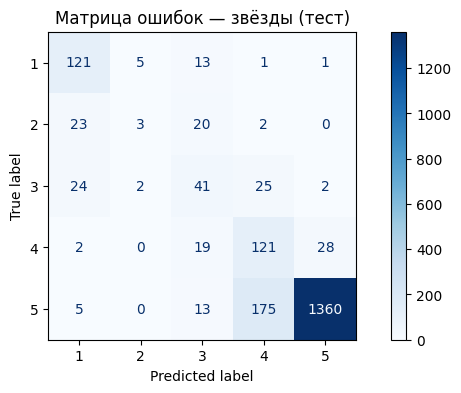

In [52]:
# ВАШ КОД
ConfusionMatrixDisplay.from_predictions(rating_test.rating, rating_prediction, labels=[1, 2, 3, 4, 5], cmap='Blues')
plt.title('Матрица ошибок — звёзды (тест)')
plt.show()

**Вопрос:** Какие оценки модель распознаёт хуже всего и с какими соседними оценками путает? Почему расхождение прогноза с оценкой не доказывает, что ошибся автор?

**Ответ:** Хуже всего распознаются оценки **2** (recall 0.06) и **3** (F1 0.41) — обе путаются в основном с соседними оценками (2↔1/3, 3↔1/4), а не с далёкими.

Расхождение прогноза с оценкой не доказывает ошибку автора: звёзды — его отдельное решение, не обязанное точно совпадать с тоном текста, а расхождение так же может быть ошибкой самой модели (macro-F1 всего 0.54).

---

### **2.6. Два читателя: ансамбль согласия**

Теперь у нас есть два «читателя» текста. Один определяет тональность, другой предсказывает звёзды. Попробуем отбирать отзывы, в которых оба прогноза расходятся с оценкой автора в одну сторону. Это **правило согласия двух моделей**: его пользу проверим чтением в части 3.

| Столбец | Правило |
|---|---|
| `star_difference` | `predicted_rating − rating`: прогноз звёзд минус оценка автора |
| `candidate` | `abs(star_difference) ≥ 2`: модель звёзд расходится с автором минимум на две звезды |
| `both` | `star_difference ≤ −2` и тональность `negative` **или** `star_difference ≥ 2` и тональность `positive` |

*Условные примеры:*

| Звёзды автора | Прогноз звёзд | Тональность | `candidate` | `both` | Как читать |
|---|---|---|---|---|---|
| 5 | 2 | negative | True | True | Текст по обеим моделям хуже оценки автора |
| 1 | 4 | positive | True | True | Текст по обеим моделям лучше оценки автора |
| 5 | 2 | neutral | True | False | Большое расхождение заметила только модель звёзд |

`both` — часть группы `candidate`, поэтому более строгое правило отберёт меньше отзывов. Рабочая гипотеза: среди них выше доля содержательных расхождений. Согласие моделей само по себе её не подтверждает: модели тоже могут ошибаться одновременно.

**1. Допишите функцию `two_readers`: она получает таблицу со столбцами `text` и `rating` и возвращает её копию с прогнозами двух моделей и столбцами из таблицы выше.** Готовая `text_features` внутри функции получает признаки; замените многоточия в прогнозах и условиях отбора.

In [53]:
def two_readers(frame):  # Прогнозы двух моделей и признаки расхождения с автором.
    frame = frame.copy()  # Не меняем исходную таблицу.
    X_sentiment = text_features(frame.text, sentiment_representation, part=1)  # Признаки для модели тональности.
    X_rating = text_features(frame.text, rating_representation, part=2)  # Признаки для модели звёзд.
    frame['sentiment'] = sentiment_model.predict(X_sentiment)  # Первый читатель: прогноз sentiment_model.
    frame['predicted_rating'] = rating_model.predict(X_rating)  # Второй читатель: прогноз rating_model.
    frame['star_difference'] = frame.predicted_rating - frame.rating  # Прогноз минус оценка автора.
    frame['candidate'] = frame.star_difference.abs() >= 2  # Расхождение не меньше двух звёзд по модулю.
    frame['both'] = ((frame.star_difference <= -2) & frame.sentiment.eq('negative')) | \
                     ((frame.star_difference >= 2) & frame.sentiment.eq('positive'))  # Обе модели против автора в одну сторону.
    frame['negative'] = frame.sentiment.eq('negative')  # Отрицательная тональность — для сводок.
    return frame  # Таблица с прогнозами.

Сначала проверим правило на отложенных отзывах: посмотрим объём отбора и конкретные тексты. Эти же прогнозы понадобятся для расчёта опорной частоты расхождений.

**2. Примените функцию к тестовой части: `rating_checked = two_readers(rating_test)`. Выведите, сколько отзывов отмечено в `candidate` и сколько в `both`, и покажите пять отзывов с `both = True` (текст, оценка, прогноз звёзд, тональность).**

In [54]:
# ВАШ КОД
rating_checked = two_readers(rating_test)

print('candidate:', rating_checked.candidate.sum())
print('both:', rating_checked.both.sum())

show(rating_checked.loc[rating_checked.both, ['text', 'rating', 'predicted_rating', 'sentiment']].sample(5, random_state=SEED))

Batches:   0%|          | 0/126 [00:00<?, ?it/s]

candidate: 63
both: 28


,text,rating,predicted_rating,sentiment
716,"Выгодное место для покупки, но ЧУДОВИЩНОЕ ДЛЯ ПРОДАВЦОВ. ЛЮДИ ЗИМОЙ В МОРОЗ НАХОДЯТСЯ НА УЛИЦЕ С 6 УТРА ДО 12 ДНЯ. В дождь тоже нет защиты для пенсионеров и инвалидов, которые и торгуют за копейки. Летом палит солнце. Продавцы должны стоять по 6-7 часов. Это просто издевательство над подилыми людьми. Губернатору Воробьеву бы надо предложить поторговать на этом рынке.",3,1,negative
1626,"Очень красивый отель. Чистенько, горничные работают очень хорошо, номера убирают часто и качественно. Детский досуг организован на высшем уровне. С едой беда, было не вкусно. Еда пресная, как в больничной столовой. Но самый главный минус это тёмненькая официантка постоянно ходит с недовольным лицом, цокает, показывает всем своим видом, что ей все это не нравится тем самым создает какой то непонятный напряг, аж портится настроение каждый раз когда заходишь в столовую. Читая комментарии заметил, что я не первый про нее пишу) Очень не приятно и я попросил бы руководство отеля обратить на это внимание. Человек приехал отдыхать, чуть забыть бытовые проблемы и тд, а тут просто каждое утро портится настроение из за ее цоканий и не приятных гримас, которые строит эта девушка. Очень было не приятно.",5,3,negative
603,Минус. При онлайн заказе если не успели за 15 минут его забрать. Он аннулируется и деньги не возвращаются. Только сегодня дети так не успели и минус 200р..,3,1,negative
1284,"Несколько лет подряд мы ездили в этот отель. Останавливались в коттедже Карасан. Чудесный коттедж на берегу пруда. Когда заказывала в последний раз коттедж, попросила, чтобы это был именно Карасан. Мне подтвердили. В результате, дали коттедж Евлана. Объяснили, что не могут забронировать желаемый коттедж. Коттедж Евлана находится за всеми остальными коттеджами и явно уступает Карасан. Даже холодильник в коттедже маленький и подтекает. Помимо этого заметили ухудшение в услугах и обслуживании. За не маленькие деньги вы столкнетесь с проблемами уборки номера, не своевременным приездом Батлеров, проблемами с резервом в ресторане. Надеюсь, это временные проблемы.",3,1,negative
56,"Плюсы:\n-Еда неплохая, вкусная \n-Можно взять с собой алкоголь\nМинус:\nМы с подругой пришли в кафе, с нами говорили на ты, ""девочки"". Мы выглядим младше своего возраста,но это не повод так говорить. Потом для просмотра паспорта пришла администратор. Она, увидев наши паспорта, сказала Блин, вы на 15 выглядите! Потом сказала, может у вас поддельные паспорта? Как шутка это не звучало, а по издевательски. Ещё сказали, А вы столько выпьете??? С таким тоном неприятным. Нам 23 года, ни в одном заведении не общались так, всегда просто смотрят паспорт и всё, ничего такого не говорят. Очень невежливо. Понимаю, что в это заведение ходят в основном 40+, но все равно это некомпетентно.\nПочему то не говорят людям, о боже, вы выглядите на 10 лет старше! А наоборот можно говорить? Даже не в суть того, что сказали, а каким тоном говорили.",3,1,negative


---

### **2.7. Перенос модели тональности: согласованность со звёздами**

Модель тональности училась на сообщениях социальной сети, а теперь читает отзывы. Проверим, как её прогнозы связаны со звёздами авторов: условно сопоставим 1–2 звезды с отрицательной оценкой, 3 — с нейтральной, 4–5 — с положительной.

Независимой разметки тональности здесь нет. Поэтому рассчитанные метрики покажут **согласованность со звёздами**, а не точность определения тональности текста. В тесте RuSentiTweet сравнение было с ручной разметкой; разность двух macro-F1 нельзя трактовать как измеренную потерю качества при переносе.

**1. Создайте `star_classes` по этому правилу (например, через `np.select`) и рассчитайте macro-F1 и accuracy прогноза `rating_checked.sentiment` относительно `star_classes`.**

<details>
<summary><b>Пример кода</b></summary>

```python
star_classes = np.select([rating_checked.rating <= 2, rating_checked.rating == 3], ['negative', 'neutral'], 'positive')
```

</details>

In [55]:
# ВАШ КОД
star_classes = np.select(
    [rating_checked.rating <= 2, rating_checked.rating == 3],
    ['negative', 'neutral'],
    'positive'
)

print('Macro-F1:', f1_score(star_classes, rating_checked.sentiment, average='macro'))
print('Accuracy:', accuracy_score(star_classes, rating_checked.sentiment))

Macro-F1: 0.5800015168479898
Accuracy: 0.7726819541375872


Общая метрика скрывает различия между оценками. В таблице долей каждая строка соответствует звёздам автора, а столбцы показывают, как модель прочитала эти отзывы. Сумма долей в строке равна единице.

**2. Постройте таблицу долей тональностей внутри каждой оценки: `pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index')`.**

In [56]:
# ВАШ КОД
show(pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index').round(3))

sentiment,negative,neutral,positive
rating,,,
1,0.879,0.113,0.007
2,0.771,0.229,0.000
3,0.606,0.372,0.021
4,0.176,0.518,0.306
5,0.008,0.153,0.838


**Вопрос:** Какая тональность чаще всего предсказывается для каждой оценки автора? Приведите доли для одной низкой и одной высокой оценки. Что показывает рассчитанная macro-F1 и почему её нельзя напрямую сравнивать с macro-F1 на тесте RuSentiTweet как измерение изменения качества?

**Ответ:** Для рейтинга 1 чаще всего предсказывается `negative` (87.9%). Для рейтинга 5 — `positive` (83.8%).

Macro-F1 (0.580) показывает лишь согласованность тональности со звёздами, а не точность определения тональности — у отзывов нет независимой разметки. Сравнивать с macro-F1 на тесте RuSentiTweet (0.74) напрямую нельзя: там «истина» — ручная разметка текста, здесь — грубое правило по оценке, да ещё и другой домен (отзывы, не твиты).

---

### **2.8. Норма расхождений**

Нужно понять, часто ли правило отбора срабатывает на обычной отложенной выборке. Рассчитаем доли `candidate` и `both` отдельно для каждой оценки автора. Для логического столбца среднее равно доле строк со значением `True`: например, 2 из 20 дают 0,10, или 10%.

Полученную таблицу `norm` будем использовать как **опорную частоту расхождений**. Она описывает наши модели на тестовых отзывах и включает как ошибки моделей, так и возможные содержательные расхождения. Это не допустимый уровень ошибок автора и не характеристика качества организации.

**Рассчитайте `norm` — средние значения `candidate` и `both` для каждой оценки автора в `rating_checked`.**

In [57]:
# ВАШ КОД: norm = rating_checked.groupby('rating')[[...]].mean()
norm = rating_checked.groupby('rating')[['candidate', 'both']].mean()
show(norm.round(3))

,candidate,both
rating,,
1,0.106,0.007
2,0.042,0.000
3,0.277,0.202
4,0.012,0.012
5,0.012,0.004


**Вопрос:** При какой оценке автора доля `candidate` максимальна? Назовите для неё доли `candidate` и `both`. Во сколько раз группа `both` меньше группы `candidate` во всём тесте? Какие отзывы более строгое правило может пропустить?

**Ответ:** Доля `candidate` максимальна при оценке **3** (0.277), для неё `both` = 0.202. По всему тесту `both` = 28, `candidate` = 63, то есть `both` примерно в **2.25 раза меньше** (63/28 ≈ 2.25). Более строгое правило `both` может пропустить реальные содержательные расхождения, где модель звёзд сильно разошлась с автором, но тональность вторая модель определила неверно или как `neutral` — расхождение настоящее, но не подтверждено в нужную сторону.

---

### **2.9. Выводы по части 2**

Приведите итоговые метрики модели звёзд на тесте и сравните их с постоянным прогнозом, указав, на какой части рассчитан каждый результат. Опишите согласованность тональности со звёздами и размер двух групп отбора. Что уже проверено численно, а что ещё нужно проверить чтением?

**Вывод:**

**Метрики модели звёзд на тесте** (`rating_test`): accuracy = 0.82, macro-F1 = 0.54, MAE = 0.218, доля ошибок ≥2 звёзды = 3.1%.

**Постоянный прогноз** (Dummy, самый частый класс) считался на `rating_valid`: accuracy = 0.779, macro-F1 = 0.175, MAE = 0.534. Части разные (тест vs валидация), но обе получены стратифицированным разделением, поэтому распределение оценок в них схоже. По accuracy модель лишь немного обгоняет Dummy (0.82 vs 0.779) — на фоне сильного перекоса в сторону 5 звёзд это ожидаемо. Разница видна в macro-F1 (0.54 vs 0.175, рост более чем в 3 раза) и MAE (0.218 vs 0.534, в 2.4 раза меньше) — модель реально распознаёт и редкие низкие оценки, а не просто угадывает большинство.

**Согласованность тональности со звёздами** (2.7): macro-F1 = 0.58, accuracy = 0.77 относительно грубого правила (1–2→negative, 3→neutral, 4–5→positive). Согласие сильнее на полюсах (рейтинг 1 → 87.9% negative, рейтинг 5 → 83.8% positive) и заметно слабее в середине шкалы (рейтинг 3 чаще читается как negative — 60.6%, а не neutral).

**Размер групп отбора** (2.8, весь тест): `candidate` = 63 отзыва, `both` = 28 — строгое правило `both` примерно в 2.25 раза меньше. Доля `candidate` максимальна у оценки 3 (27.7%, из них `both` — 20.2%).

**Проверено численно:** качество модели звёзд на тесте, согласованность тональности со звёздами по грубому правилу, объём и распределение групп `candidate`/`both` по оценкам.

**Нужно проверить чтением (часть 3):** действительно ли отзывы в группах `candidate`/`both` содержат содержательные расхождения текста и оценки, а не просто ошибки моделей — согласие двух моделей само по себе этого не доказывает.

---

## **Часть 3. Отзывы выбранной территории**

**Задача:** применить двух читателей к свежим отзывам выбранной территории, проверить чтением, помогает ли правило согласия находить настоящие расхождения, выделить организации, где расхождений больше обычного, сопоставить рейтинги карточек с содержанием отзывов и сравнить две территории.

Территорию выбираете вы: город по названию, прямоугольник или полигон, нарисованный на карте. В эталонном решении примером служат Фрязино и Щёлково Московской области.

### **3.1. Выбор территории и сбор отзывов**

[Сборщик отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews) ищет организации выбранных категорий внутри заданной территории и читает их публичные отзывы. Результат — две связанные таблицы:

| Объект | Содержание |
|---|---|
| `result.organizations` | Название, адрес, координаты, рубрики, рейтинг карточки (`rating`), число оценок (`ratings_count`) и отзывов (`reviews_count`), состояние сбора |
| `result.reviews` | Текст, дата, звёзды автора (`rating`), автор и `organization_id` |
| `result.confirmed_reviews()` | Отзывы с подтверждённым полным текстом, датой и оценкой 1–5 |
| `result.to_geopandas()` | Организации как точки в системе координат WGS84 (EPSG:4326) |

Таблицы связаны по `organization_id`. Обратите внимание: `organizations.rating` — рейтинг карточки по всем оценкам, `reviews.rating` — звёзды одного отзыва.

In [58]:
# Устанавливаем сборщик отзывов из репозитория.
%pip install -q git+https://github.com/Alexandre77777/yandex-maps-reviews.git@ce37d74b5cb76018d043dba099d612d7bc2ecd2f

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [59]:
import json  # Сохраняем GeoJSON.
import osmnx as ox  # Получаем границы из OpenStreetMap.
import folium  # Интерактивные карты.
from folium.plugins import Draw  # Рисование своей территории.
from yandex_maps_reviews import collect_area, list_categories  # Сборщик отзывов.

categories = pd.DataFrame.from_dict(list_categories(), orient='index')  # Каталог категорий.
show(categories.loc[['cafe', 'school', 'pharmacy', 'clinic', 'grocery', 'residential'], ['label', 'query']])  # Примеры категорий.
# Весь каталог: show(categories). Ключи из индекса передаются в tags.

,label,query
cafe,Кафе,кафе
school,Школы,общеобразовательные школы
pharmacy,Аптеки,аптеки
clinic,Медицинские центры,медицинские центры
grocery,Продуктовые магазины,продуктовые магазины
residential,Жилые комплексы,жилые комплексы


In [60]:
# Готовые функции: граница города и подготовка отзывов
def city_boundary(name, filename):  # Граница населённого пункта из OSM в файл GeoJSON.
    boundary = ox.geocode_to_gdf(name).to_crs(4326)  # Полигон в долготе и широте.
    Path(filename).write_text(boundary.to_json(), encoding='utf-8')  # Сохраняем для сборщика.
    show(boundary[['display_name']])  # Проверяем, что найдено.
    return boundary  # Полигон для карты.

def prepare_reviews(result):  # Подтверждённые отзывы с названием и адресом организации.
    names = result.organizations[['organization_id', 'name', 'address']].rename(columns={'name': 'organization_name', 'address': 'organization_address'})  # Подписи.
    reviews = result.confirmed_reviews().merge(names, on='organization_id', how='left', validate='many_to_one')  # Связываем таблицы.
    return reviews.reset_index(drop=True)  # Последовательные индексы.

def area_map(boundary):  # Карта найденной границы с инструментом рисования.
    west, south, east, north = boundary.total_bounds  # Охват границы.
    canvas = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12, tiles='Esri.WorldImagery')  # Центр карты на спутниковой подложке.
    folium.GeoJson(boundary[['geometry']].to_json(), name='Граница OSM', style_function=lambda _: {'color': 'yellow', 'weight': 3, 'fillOpacity': 0.05}).add_to(canvas)  # Контур территории.
    Draw(export=True, filename='drawn_area.geojson', draw_options={'circle': False, 'circlemarker': False, 'marker': False, 'polyline': False}).add_to(canvas)  # Прямоугольник и полигон.
    return canvas  # Карта для проверки.

**Как задать территорию.** Выберите **один** способ:

- **город по названию:** `city_boundary('Город, регион, Россия', 'area_a.geojson')`, затем `area_a = {'geometry': 'area_a.geojson'}`. Указывайте регион: одноимённых городов много;
- **прямоугольник:** `area_a = {'bbox': [запад, юг, восток, север]}` — долгота и широта в градусах;
- **свой полигон:** получите границу города, откройте `area_map(boundary_a)`, нарисуйте прямоугольник или многоугольник, нажмите **Export**, загрузите `drawn_area.geojson` в Colab и задайте `area_a = {'geometry': 'drawn_area.geojson'}`.

Карта помогает проверить, что выбрана нужная территория. При способе с прямоугольником получите границу города как ориентир и сопоставьте с ней указанные координаты.

**Как выбрать объём.** Для первого сбора ориентируйтесь на 3–7 минут: например, 2–3 категории, `max_orgs=3` и `max_reviews=20`. Это стартовые значения, а не требование: время зависит от числа найденных карточек и скорости сайта. `max_orgs` ограничивает число организаций на категорию, `max_reviews` — число свежих отзывов каждой организации. Для сравнения средних ниже будут использоваться организации с не менее чем `MIN_REVIEWS` отзывами; небольшая выборка подходит для знакомства с результатами, но даёт менее устойчивые выводы о территории.

Повторный запуск с теми же параметрами использует сохранённый сбор; при удалении среды Colab данные пропадают. Если сайт временно ограничит доступ, подождите перед повторным запуском.

**1. Задайте территорию `area_a`, список категорий `tags`, лимиты `max_orgs`, `max_reviews` и папку `folder_a`. Покажите территорию на карте.**

<details>
<summary><b>Пример кода</b></summary>

```python
boundary_a = city_boundary('Фрязино, Московская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery', 'school']
max_orgs, max_reviews = 5, 25
folder_a = Path('reviews_a')
area_map(boundary_a)
```

</details>

In [61]:
# ВАШ КОД
boundary_a = city_boundary('Мытищи, Московская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery', 'school']
max_orgs, max_reviews = 5, 25
folder_a = Path('reviews_a')
area_map(boundary_a)

,display_name
0,"Mytishchi, Mytishchi Urban Okrug, Moscow Oblast, Central Federal District, Russia"


In [62]:
result_a = collect_area(**area_a, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder_a)  # Собираем организации и отзывы.
reviews_a = prepare_reviews(result_a)  # Подтверждённые отзывы с названиями.
print('Организаций / подтверждённых отзывов:', len(result_a.organizations), len(reviews_a))  # Объём сбора.
show(result_a.organizations[['name', 'address', 'rating', 'ratings_count', 'review_status', 'saved_reviews']])  # Состояние сбора.

Организаций / подтверждённых отзывов: 20 495


,name,address,rating,ratings_count,review_status,saved_reviews
0,ElMantra кофе,"Мытищи, ул. Разведчика Абеля, 3",5.0,53,capped,25
1,Гастробар Вино и Булки,"Мытищи, ул. Разведчика Абеля, 5",5.0,1538,capped,25
2,Здрасте,"Мытищи, просп. Астрахова, 14",4.9,505,capped,25
3,Правильное Пространство,"Мытищи, ул. Мира, 41",5.0,48,capped,25
4,Додо Пицца,"Мытищи, Лётная ул., 17",5.0,1970,capped,25
5,Ригла,"Мытищи, ул. Мира, 49",4.5,53,complete,20
6,Ригла,"Мытищи, ул. Веры Волошиной, 9/24",4.4,282,capped,25
7,Ригла,"Мытищи, ул. Сукромка, 5",4.6,262,capped,25
8,Ригла,"Мытищи, Юбилейная ул., 38",4.3,296,capped,25
9,Ригла,"Мытищи, Олимпийский просп., 10",4.2,165,capped,25


| Статус карточки | Что означает |
|---|---|
| `complete` | Получены все отзывы, число совпало со счётчиком страницы |
| `capped` | Достигнут лимит `max_reviews`: собраны самые свежие отзывы |
| `stalled` | Новые записи перестали поступать, полнота не подтверждена |
| `incomplete_fields` | У части записей нет обязательных полей |

Статус относится к сбору, а не к качеству организации. Поиск возвращает доступную выдачу, а не полный реестр организаций территории. [Подробнее о статусах](https://github.com/Alexandre77777/yandex-maps-reviews/blob/main/docs/USAGE.md#статусы-и-диагностика).

**Описание выборки:** укажите территорию и способ её задания, категории, дату сбора, лимиты, число организаций и подтверждённых отзывов, распределение статусов. Для каких организаций собраны не все отзывы? Можно ли по этой выборке судить обо всех организациях территории?

**Описание выборки:** территория — город Мытищи, Московская область (задана по названию через `city_boundary`/`area_a = {'geometry': ...}`). Категории: `cafe`, `pharmacy`, `grocery`, `school`. Дата сбора — 18.10.2026. Лимиты: `max_orgs=5` (на категорию), `max_reviews=25` (на организацию). Собрано 20 организаций и 500 подтверждённых отзывов.

Распределение статусов: все 20 организаций (100%) — `capped`.

**Не все отзывы собраны ни для одной организации** — статус `capped` у всех 20, и у большинства число оценок (`ratings_count`) намного превышает 25 сохранённых отзывов (например, у «Токио-City» — 13314 оценок, у «Кодру» — 3312, у «Чинтамани» — 894, при 25 сохранённых отзывах у каждой). То есть собраны только самые свежие отзывы, а не вся история.

**Судить обо всех организациях территории по этой выборке нельзя**: охвачены лишь 4 категории из возможных, максимум 5 организаций на категорию (это часть выдачи поиска, а не полный реестр), и у каждой организации — только срез последних отзывов, а не полная картина. Выборка подходит для знакомства с данными, но не для статистически устойчивых выводов обо всех организациях Мытищ.

---

### **3.2. Два читателя на новых отзывах**

Применим готовую `two_readers` к новым отзывам без дообучения. Для каждого отзыва возьмём из `norm.both` опорную частоту, соответствующую звёздам автора, и запишем её в `expected_both`.

**Как получается ожидаемое число.** *Условный пример:* в организации 10 отзывов на 5 звёзд и 5 отзывов на 3 звезды. Если опорные частоты `both` равны 1% и 10%, ожидается `10 × 0,01 + 5 × 0,10 = 0,6` случая. Ожидание может быть дробным; фактически отобранных отзывов всегда целое число. Поэтому суммируем `expected_both`, а не усредняем его.

**1. Получите `reviews_a = two_readers(reviews_a)` и добавьте столбец `expected_both` — опорную частоту для оценки автора: `reviews_a.rating.map(norm.both)`.**

**2. Выведите число отзывов в группах `candidate` и `both` и сравните наблюдаемое число случаев `both` с ожидаемым (сумма `expected_both`).**

In [63]:
# ВАШ КОД
reviews_a = two_readers(reviews_a)
reviews_a['expected_both'] = reviews_a.rating.map(norm.both)

print('candidate:', reviews_a.candidate.sum())
print('both (наблюдается):', reviews_a.both.sum())
print('both (ожидалось):', reviews_a.expected_both.sum())

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

candidate: 34
both (наблюдается): 11
both (ожидалось): 6.8663707129082


**Вопрос:** Сколько случаев `both` наблюдается и сколько ожидалось по опорной частоте? Во сколько раз они различаются? Назовите две возможные причины расхождения; какие данные помогли бы отличить содержательное расхождение от ошибки модели?

**Ответ:** В группе `both` оказалось 11 отзывов вместо ожидаемых 6,17 — это примерно в 1,78 раза больше.

1. Отзывы из Мытищ отличаются от остальных: в них упоминаются конкретные кафе, аптеки, школы и магазины. Возможно, в этих отзывах чаще встречается ситуация, когда текст не совпадает с поставленной оценкой.
2. Модели тоже могут ошибаться. Например, свежие отзывы могут отличаться по стилю, длине или используемым словам, из-за чего модель неправильно определяет тональность или предсказывает количество звёзд.


---

### **3.3. Проверка чтением: работает ли ансамбль согласия**

Проверим рабочую гипотезу: среди отзывов, отобранных обеими моделями, доля содержательных расхождений выше, чем среди отзывов, отмеченных только моделью звёзд.

Готовая функция отбирает до 15 отзывов из каждой группы и перемешивает их. При чтении видны название организации, текст и звёзды автора, а прогнозы и группа скрыты. Сначала вы оцените содержание по единым правилам, затем раскроете группы и сравните результаты. Это помогает уменьшить влияние ожиданий от моделей.

До 30 отзывов — небольшой ручной разбор. Он позволяет увидеть типичные случаи и получить предварительные доли, но не гарантирует устойчивого различия между способами отбора.

In [64]:
# Готовые функции: выборка для чтения вслепую и раскрытие групп
def reading_sample(reviews, n=15):  # До n отзывов из каждой группы в случайном порядке.
    both = reviews.loc[reviews.both]  # Обе модели против автора.
    only = reviews.loc[reviews.candidate & ~reviews.both]  # Только модель звёзд.
    sample = pd.concat([both.sample(min(n, len(both)), random_state=SEED), only.sample(min(n, len(only)), random_state=SEED)])  # Две группы.
    return sample.sample(frac=1, random_state=SEED).reset_index(drop=True)  # Перемешиваем.

def reveal(sample, types):  # Сопоставляем ваши типы с группами.
    reading = sample.assign(type=types, group=np.where(sample.both, 'обе модели', 'только модель звёзд'))  # Добавляем тип и группу.
    reading['content'] = reading.type.isin(['знак', 'резче'])  # Настоящее расхождение текста и оценки.
    reading['model_error'] = reading.type.isin(['ошибка', 'ирония'])  # Ошибка моделей.
    show(pd.crosstab(reading.group, reading.type, margins=True))  # Типы в каждой группе.
    show(reading.groupby('group')[['content', 'model_error']].agg(['sum', 'mean']).round(2))  # Число и доля.
    return reading  # Таблица разбора.

sample_a = reading_sample(reviews_a)  # Отзывы для чтения.
show(sample_a[['organization_name', 'rating', 'text']])  # Текст и звёзды автора.

,organization_name,rating,text
0,"Средняя общеобразовательная школа № 32, корпус № 1",5,"Где-то здесь гуляет свежий отзыв от недородителя, которая обижена на жизнь и не знает, на ком сорвать негативные эмоции. Люди, которые полностью удовлетворены своей жизнью, не будут заниматься подобным. 😛 Купите себе кока-колу и успокойтесь))\n \nНе нужно так отзываться об этой школе и прекрасных учителях!\n\nЯ лично крайне благодарна судьбе за то, что мне посчастливилось учиться в этих стенах. Суперские школьные годы."
1,Eurospar,1,"Магазин вроде не плохой, всегда кушаем там, сегодня взяли картошку фри и наггетсы и роллы, приехали домой животы разболелись, разочаровалась кулинарией."
2,ВкусВилл,1,Попросил ребенку трубочку для напитков! На ответили у нас трубочки только для наших напитков))) смех
3,Ригла,1,"Аптека с 9:00, время 9:26, никаких признаков жизни"
4,ВкусВилл,5,Да я вообще люблю эту сеть магазинов. Хоть как-то потаются следить за составом продуктов).
5,Eurospar,3,"Сегодня приобрела лапшу удон, в отделе готовой еды, на вид была очень даже ничего, но когда я её переложила дома в тарелку, то меня очень удивило количество масла, было ощущение, что её готовили во фритюре. Да и вообще качество готовой продукции сильно упало. Работники которые обслуживают, смотрят на тебя с таким выражением лица, как будто ты им должен, причём много и по жизни."
6,Гастробар Вино и Булки,1,"С первого дня переодически посещаю этот ресторан вместе с женой\nТак последнее время что бы ты не заказал, делают тяп ляп\nЖена днем заказывает на вынос кашу с баночном и клубникой, в итоге каша с бананом \nЯ вечером заказываю Бурге с котлетой из мраморной говядины и это не бургер а холодный кусок не пойми чего"
7,Правильное Пространство,5,"Обычное кафе, не сильно впечатлило, многих блюд из меню по факту не было. В кофе не было кофе, по вкусу одно молоко. «Большой завтрак» за 1000 руб был скудный и скучный, мужчина остался голодным. Второй раз бы не пошла."
8,Ригла,1,"""Хорошая"" аптека!!!\nЦена в два раза выше, чем везде.\nНикогда туда не приду."
9,Ригла,2,Дорогая аптека!!!


**1. Прочитайте каждый отзыв и определите его тип.** Запишите коды в список `types` в порядке строк таблицы (первый элемент — для строки 0).

| Код | Тип | Условный пример |
|---|---|---|
| `'знак'` | Текст и оценка противоположны | Подробная жалоба на обман с ценой — 5 звёзд; «всё понравилось» — 1 звезда |
| `'резче'` | Направление оценки совпадает, но текст заметно резче или мягче звёзд | Одни недостатки — 3 звезды |
| `'смешанный'` | Есть и плюсы, и минусы; оценка зависит от приоритетов автора | «Еда вкусная, но ждали час» — 4 звезды |
| `'ирония'` | Текст согласуется со звёздами, но ироническая фраза могла запутать модель | «Спасибо, отличная работа» о плесени в покупке — 1 звезда |
| `'ошибка'` | Текст согласуется со звёздами, явной иронии нет | «Школа топ» — 5 звёзд |
| `'не по теме'` | Текст не об организации | Сообщение о неверной точке на карте |

Сначала сопоставьте содержание со звёздами, затем выберите один код. Если текст явно расходится с оценкой, используйте `'знак'` или `'резче'`, даже если в нём есть ирония. Если есть существенные плюсы и минусы без явного противоречия оценке — `'смешанный'`. Коды `'ошибка'` и `'ирония'` означают, что по вашему прочтению текст согласуется со звёздами, хотя модели включили его в отбор.

В таблице сравнения содержательными расхождениями считаем `'знак'` и `'резче'`, ошибками моделей — `'ошибка'` и `'ирония'`. Неоднозначные случаи остаются отдельно.

In [65]:
types = [
    'ошибка', 'ошибка', 'ошибка', 'ошибка', 'резче', 'резче', 'ошибка',
    'смешанный', 'знак', 'смешанный', 'смешанный', 'ошибка', 'не по теме',
    'резче', 'смешанный', 'ошибка', 'ошибка', 'ошибка', 'ошибка', 'ошибка',
    'ошибка', 'резче', 'смешанный', 'смешанный', 'ошибка', 'смешанный',
]

Теперь сопоставим вашу оценку содержания со способом отбора. `reveal` покажет число отзывов каждого типа и долю содержательных расхождений и ошибок модели внутри каждой группы.

**2. Раскройте группы:** `reading_a = reveal(sample_a, types)`.

In [66]:
# ВАШ КОД
reading_a = reveal(sample_a, types)

type,знак,не по теме,ошибка,резче,смешанный,All
group,,,,,,
обе модели,0,0,2,3,6,11
только модель звёзд,1,1,11,1,1,15
All,1,1,13,4,7,26


content       model_error      
                        sum  mean         sum  mean
group                                              
обе модели                3  0.27           2  0.18
только модель звёзд       2  0.13          11  0.73

**Вопрос:** Сколько содержательных расхождений и ошибок модели оказалось в каждой группе? Приведите числа и доли, а также по одному примеру каждого встреченного типа с короткой цитатой. Поддерживает ли этот разбор гипотезу о пользе согласия моделей? Насколько уверенно можно обобщать результат небольшой выборки?

**Ответ:** В группе, где обе модели согласились (`n=11`), содержательные расхождения обнаружены в 3 отзывах (27%), а ошибки моделей — в 2 (18%). В группе, где сработала только модель оценки (`n=15`), содержательных расхождений было 2 (13%), а ошибок — 11 (73%).

Примеры: `знак` — отзыв о «Дикси» с оценкой 5, хотя автор пишет, что на кассе «нагло обманывает»; `резче` — отзыв о «Кодру» с оценкой 4 и жалобой, что «даже мамалыга не та»; `смешанный` — отзыв о «Кодру» с оценкой 3, где автор хвалит вино и голубцы, но ругает сервис. Примеры ошибок: `ошибка` — отзыв о школе № 9 с оценкой 1 и текстом «оч плохо»; `не по теме` — отзыв о школе № 32, корп. 1, с оценкой 5, в котором автор задаёт вопрос о закрытых площадках.

Результаты поддерживают гипотезу: когда обе модели согласны, содержательные расхождения встречаются чаще, а ошибки — реже. Разница в количестве ошибок статистически значима (точный тест Фишера, p ≈ 0,015), а разница по содержательным расхождениям — нет (p ≈ 0,62).

Однако делать окончательные выводы пока рано: выборка небольшая (11 и 15 отзывов), отзывы оценивал один человек, а данные взяты только с одной территории. Поэтому результаты ещё нужно проверить на большей выборке.

---

### **3.4. Организации, где расхождений больше обычного**

> 📚 **Подсказка:** [**Занятие 1: группировка groupby**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W#scrollTo=baa512e4); [**GroupBy.agg**](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html).

Перейдём от отдельных отзывов к организациям. Сравнение только по доле `both` зависит от состава оценок: организация с множеством трёхзвёздочных отзывов может чаще попадать в отбор уже потому, что для этой оценки опорная частота выше. Поэтому сопоставим число отобранных отзывов с ожиданием, рассчитанным по звёздам её авторов.

Учтём также общий уровень территории: умножим исходное ожидание на отношение «наблюдаемое / ожидаемое» по всем её отзывам. *Условный пример:* на территории 60 случаев при ожидаемых 40, коэффициент равен 1,5. Для организации с исходным ожиданием 0,6 скорректированное ожидание составит 0,9.

| Показатель | Как читать |
|---|---|
| `observed_both` | Фактическое число отзывов, отобранных обеими моделями |
| `expected_both_zone` | Ожидаемое число с учётом звёзд авторов и общего уровня территории |
| `relative_ratio` | Наблюдаемое / ожидаемое: 1 — на ожидаемом уровне, больше 1 — выше |
| `p_value` | Насколько необычно получить не меньше наблюдаемого числа при принятом ожидании и модели Пуассона |

Для предварительной оценки редких случаев используем `poisson.sf(observed − 1, expected)`. Например, один случай при ожидании 0,2 даёт большое отношение 5, но такое превышение ещё может возникать случайно. Малое `p_value` помогает выбрать организацию для чтения; это не вероятность ошибки автора или плохого качества организации. [Распределение Пуассона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).

Ожидание оценено по данным, отзывы одной организации могут быть зависимы, а проверок сразу много. Здесь `p_value` используется как приближённый ориентир для разбора. Для подтверждённого статистического вывода потребуются проверка предположений и учёт [множественных проверок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

Функция `organization_summary` сгруппирует отзывы по организации и присоединит сведения её карточки. На выходе будет одна строка на организацию: объём выборки, средние оценки, доли и показатели отбора.

**1. Допишите функцию `organization_summary`.** В `agg` добавьте средний прогноз звёзд (`mean_predicted_stars`) и долю отрицательной тональности (`negative_share`, среднее столбца `negative`). В конце рассчитайте разницу рейтинга карточки (`rating` из таблицы организаций) со средними звёздами собранных отзывов и со средним прогнозом — она понадобится в 3.5.

In [67]:
from scipy.stats import poisson  # Распределение Пуассона.

def organization_summary(reviews, organizations):  # Сводка по организациям территории.
    summary = reviews.groupby('organization_id').agg(  # Показатели по отзывам организации.
        analyzed_reviews=('text', 'size'),  # Число отзывов в анализе.
        mean_review_stars=('rating', 'mean'),  # Средние звёзды авторов.
        mean_predicted_stars=('predicted_rating', 'mean'),  # Средний прогноз звёзд.
        negative_share=('negative', 'mean'),  # Доля отрицательной тональности.
        observed_both=('both', 'sum'),  # Наблюдаемое число случаев both.
        expected_both=('expected_both', 'sum'),  # Ожидаемое по норме.
    ).astype(float)  # Обычные числа с плавающей точкой.
    zone_ratio = summary.observed_both.sum() / summary.expected_both.sum()  # Уровень всей территории относительно нормы.
    summary['expected_both_zone'] = summary.expected_both * zone_ratio  # Ожидаемое с учётом уровня территории.
    summary['relative_ratio'] = summary.observed_both / summary.expected_both_zone  # Наблюдаемое / ожидаемое.
    summary['p_value'] = poisson.sf(summary.observed_both - 1, summary.expected_both_zone)  # Вероятность не меньшего числа случаев.
    result = organizations.merge(summary, left_on='organization_id', right_index=True)  # Добавляем сведения карточек.
    result['card_minus_stars'] = result.rating - result.mean_review_stars  # Карточка минус средние звёзды собранных отзывов.
    result['card_minus_texts'] = result.rating - result.mean_predicted_stars  # Карточка минус средний прогноз звёзд.
    return result  # Таблица организаций.

**2. Получите `org_a = organization_summary(reviews_a, result_a.organizations)` и выведите пять организаций с наименьшим `p_value`: название, категорию (`found_by`), число отзывов, наблюдаемое и ожидаемое число случаев, `p_value`.**

In [68]:
# ВАШ КОД
org_a = organization_summary(reviews_a, result_a.organizations)  # Сводка по организациям.
show(org_a.nsmallest(5, 'p_value')[['name', 'found_by', 'analyzed_reviews', 'observed_both', 'expected_both_zone', 'p_value']])  # Пять организаций с наименьшим p_value.

,name,found_by,analyzed_reviews,observed_both,expected_both_zone,p_value
19,Средняя общеобразовательная школа № 35,['school'],25.0,2.0,0.510875,0.093520
3,Правильное Пространство,['cafe'],25.0,1.0,0.153717,0.142485
15,"Средняя общеобразовательная школа № 32, корпус № 1",['school'],25.0,1.0,0.197409,0.179145
16,Средняя общеобразовательная школа № 9,['school'],25.0,1.0,0.217082,0.195136
12,ВкусВилл,['grocery'],25.0,2.0,1.137069,0.314518


**3. Прочитайте отзывы с `both = True` у первой организации списка: текст, звёзды автора, прогноз звёзд и тональность.**

In [69]:
# ВАШ КОД
first_org = org_a.nsmallest(1, 'p_value').iloc[0]  # Организация с наименьшим p_value.
show(reviews_a.loc[(reviews_a.organization_id == first_org.organization_id) & reviews_a.both, ['text', 'rating', 'predicted_rating', 'sentiment']])  # Отзывы, отобранные обеими моделями.

,text,rating,predicted_rating,sentiment
472,"Может преподаватели в этой школе и хорошие, но мы пока не можем добиться ответа от администрации школы. Подали заявление о переводе ребёнка в школу и администрация всячески затягивает решение этого вопроса. Первый раз подали заявление 31.08.2026 г, пришёл 02.09.2026 отказ. Мы три дня ходили в школу всей семьёй. Ответ был один...Ждите, с вами хочет поговорить директор. Ждала звонка 3.09, 4.09, 05.09, 06.09, 7.09... 07.09.2026 опять подаю заявление. Теперь уже не из дома, еду в МФЦ. Вечером звонок, ждите, с вами хочет поговорит директор. И опять ждите... Осталось только одно, подать жалобу в Министерство Образования, вот и весь разговор. А хотелось вести диалог по-доброму.\nХочу дополнить свой отзыв после общения с директором и учителями школы. Коллектив хороший, видно, что учителя с опытом, все настроены очень доброжелательно. Да, строгость и дисциплина присутствуют, ну а как по другому с подростками?\nСамое главное, что самому ребёнка все очень понравилось. И учителя и классы и ребята. Я сама, пока 2 дня тусовалась в школе, почувствовала себя снова ученицей. Одну звезду сняла за книги. Почему то их в наличии, в библиотеке, не оказалось...",4,1,negative
491,"Я хочу оставить отзыв о школе, в которой училась и получила не только знания, но и важные жизненные уроки благодаря некоторым педагогам. Я благодарна педагогу-психологу Дамбраускене Алене Вячеславовне — за ее заботу, терпение и внимательное отношение к каждому ученику создавали атмосферу доверия и поддержки. Именно благодаря ей учеба становилась легче и приятнее.\n\nУчитель математики Лексонова Ирина Вениаминовна — настоящий профессионал, она умела делать сложное понятным и интересным. Благодаря ее урокам математика перестала казаться страшной и стала увлекательной дисциплиной.\n\nУчитель иностранного языка Радецкая Ольга Викторовна — вдохновительница, которая развивает интерес к иностранным языкам. Ее уроки были насыщенными, креативными и мотивирующими.\n\nУчитель истории и обществознания Мануйлова Оксана Владимировна — человек, который научил мыслить аналитически и видеть связь прошлого с настоящим.\n\nИменно эти педагоги сделали школьное время насыщенным и вдохновляющим. Я благодарена им за их труд, терпение и профессионализмизм.",3,5,positive


**Вопрос:** Сколько организаций имеют `p_value < 0,05` в предварительном расчёте? Для первой организации приведите наблюдаемое и ожидаемое число и объясните прочитанные отзывы. Какие возможные причины превышения они показывают? Почему одного отношения 5 при наблюдаемом 1 и ожидаемом 0,2 недостаточно для уверенного вывода?

**Ответ:** Ноль. Среди пяти организаций с самым маленьким p_value минимальное значение — 0,094 (Школа №35), то есть даже лидер по необычности превышения не проходит порог 0,05. Значит, во всей территории ни одна организация не даёт статистически заметного отклонения при таком предварительном расчёте.

---

### **3.5. Рейтинг карточки и содержание отзывов**

У организации есть три разные сводки: рейтинг карточки, средние звёзды собранных отзывов и средний прогноз по их текстам. Рейтинг карточки учитывает другой состав оценок, включая давние и без текста; наш сбор ограничен свежими отзывами. Сравнение покажет, насколько эти источники согласуются, и поможет выбрать случаи для чтения.

`card_minus_stars` — рейтинг карточки минус средние звёзды собранных отзывов; `card_minus_texts` — рейтинг карточки минус средний прогноз. Положительная разность означает, что рейтинг карточки выше соответствующей средней. *Условный пример:* карточка 4,5, свежие отзывы в среднем 3,5 — разность равна +1 звезде.

Чтобы одна-две записи не определяли среднюю, сравнивайте организации с не менее чем `MIN_REVIEWS` отзывами. Этот порог ограничивает самые малые выборки, но сам по себе не гарантирует точность.

**1. Задайте `MIN_REVIEWS` (например, 10) и выведите описательную статистику `card_minus_stars` и `card_minus_texts` для организаций с `analyzed_reviews ≥ MIN_REVIEWS`. Рассчитайте корреляцию рейтинга карточки со средними звёздами собранных отзывов.**

In [70]:
# ВАШ КОД
MIN_REVIEWS = 10  # Минимальный объём выборки для сравнения.
reliable_a = org_a.loc[org_a.analyzed_reviews >= MIN_REVIEWS]  # Организации с достаточным числом отзывов.
show(reliable_a[['card_minus_stars', 'card_minus_texts']].describe())  # Описательная статистика разниц.
print('Корреляция рейтинга карточки со средними звёздами отзывов:', reliable_a.rating.corr(reliable_a.mean_review_stars))

,card_minus_stars,card_minus_texts
count,20.0,20.0
mean,0.6945,0.7475
std,0.614042,0.591028
min,-0.36,-0.28
25%,0.35,0.475
50%,0.665,0.75
75%,0.965,0.925
max,2.28,2.36


Корреляция рейтинга карточки со средними звёздами отзывов: 0.3895823381665275


Проверим, похожа ли разница у организаций разных категорий. `found_by` хранит список категорий, по которым найдена организация; `explode` создаёт отдельную строку для каждого элемента списка. Организация, найденная по нескольким категориям, попадёт в каждую из них.

**2. Сравните среднюю разницу `card_minus_stars` по категориям.** Сначала разверните `found_by` методом `explode`, затем рассчитайте среднюю разность и число организаций каждой категории.

In [71]:
# ВАШ КОД: reliable_a.explode('found_by').groupby('found_by')...
show(reliable_a.explode('found_by').groupby('found_by').card_minus_stars.agg(['mean', 'size']))  # Средняя разница и число организаций по категориям.

,mean,size
found_by,,
cafe,0.692,5
grocery,0.856,5
pharmacy,0.958,5
school,0.272,5


**3. Сформулируйте две гипотезы**, объясняющие разницу между карточкой и свежими отзывами, и **проверьте одну** на своих данных.

| № | Гипотеза | Чем проверить |
|---|---|---|
| 1 | Карточка завышена там, где много оценок без текста: если автор не пишет отзыв, он реже ставит низкую оценку (ставить 1★ с объяснением — эмоциональное усилие, а молчаливую низкую оценку проще не поставить вовсе), поэтому rating карточки тянется вверх относительно текстовых отзывов | Корреляция card_minus_stars с долей безтекстовых оценок 1 − reviews_count/ratings_count |
| 2 | Разница связана с эффектом свежести: карточка усредняет вообще все оценки за всё время, а наш сбор у организаций со статусом capped ограничен самыми свежими max_reviews отзывами — если качество менялось, свежая выборка систематически отличается от долгосрочной карточки | Сравнение card_minus_stars между организациями review_status == 'capped' и остальными (complete/stalled) |

<details>
<summary><b>Подсказка к гипотезам</b></summary>

В таблице организаций есть `ratings_count` — число всех оценок — и `reviews_count` — число отзывов с текстом. Если многие ставят оценку без текста, доля таких оценок `1 − reviews_count / ratings_count` может быть связана с разницей. Возможно, разница больше у популярных организаций с большим `ratings_count`. Может ли влиять то, что `max_reviews` оставляет только самые свежие отзывы? Проверку можно выполнить корреляцией или сравнением групп выше и ниже медианы.

</details>

In [72]:
# ВАШ КОД
textless_share = 1 - reliable_a.reviews_count / reliable_a.ratings_count  # Доля оценок без текста.
print('Корреляция доли безтекстовых оценок с card_minus_stars:', textless_share.corr(reliable_a.card_minus_stars))
show(pd.DataFrame({'textless_share': textless_share, 'card_minus_stars': reliable_a.card_minus_stars}).describe())  # Описательная статистика для контекста.

Корреляция доли безтекстовых оценок с card_minus_stars: 0.04989813654871751


,textless_share,card_minus_stars
count,20.0,20.0
mean,0.559264,0.6945
std,0.179698,0.614042
min,0.125,-0.36
25%,0.464262,0.35
50%,0.623377,0.665
75%,0.688427,0.965
max,0.783505,2.28


**Гипотезы и результат проверки:** Гипотеза 1 — разница объясняется долей оценок без текста (1 − reviews_count/ratings_count): где такая доля выше, карточка завышена сильнее, потому что молчаливую низкую оценку ставить проще, чем писать негативный отзыв. Гипотеза 2 — разница связана со свежестью: карточка усредняет вообще все оценки за всё время, а собранная выборка у организаций со статусом capped ограничена самыми свежими отзывами, и при изменении качества со временем это даёт систематический сдвиг.

Проверка гипотезы 1 на reliable_a (n=20, analyzed_reviews ≥ 10): корреляция textless_share с card_minus_stars ≈ 0,05 — практически нулевая, то есть доля безтекстовых оценок разницу не объясняет. При этом сама разница заметная и устойчиво положительная: средняя card_minus_stars ≈ 0,69★ (от −0,36 до 2,28), а доля безтекстовых оценок варьируется широко (12,5–78,4%) без всякой связи с этим смещением. Гипотеза 1 не подтвердилась; более вероятный кандидат — эффект свежести (гипотеза 2) или различия по категориям, которые разбирались в предыдущем шаге.

**Вопрос:** На сколько в среднем рейтинг карточки отличается от свежих отзывов с текстом? У каких категорий разница больше? Что вы посоветуете человеку, который выбирает организацию по рейтингу карточки?

**Ответ:** В среднем рейтинг карточки выше свежих отзывов с текстом на 0,69★ (card_minus_stars, n=20 организаций с ≥10 отзывами) и на 0,75★ выше прогноза модели по содержанию (card_minus_texts); разброс большой (std ≈ 0,6, от −0,36 до 2,28), то есть встречаются и организации, где карточка ниже свежих отзывов.

По категориям разница сильно различается: больше всего у аптек (0,96★) и продуктовых (0,86★), заметно меньше у кафе (0,69★) и минимальна у школ (0,27★) — у школ карточка почти совпадает со свежими отзывами, а у аптек и магазинов расходится почти на целую звезду.

Человеку, выбирающему организацию по рейтингу карточки, можно посоветовать не доверять этой цифре буквально — особенно для аптек и продуктовых, где разрыв больше звезды. Корреляция рейтинга карточки со средними звёздами свежих отзывов умеренная (r ≈ 0,39, то есть объясняет лишь около 15% разброса), значит карточка — слабый прогноз актуального опыта: она усредняет оценки за всё время, включая давние и без текста, а свежие текстовые отзывы могут отражать более текущее положение дел. Разумнее читать несколько последних отзывов с текстом, особенно в категориях с большим разрывом, и относиться к рейтингу карточки как к долгосрочному ориентиру, а не оценке «сейчас».

---

### **3.6. Карты**

Карты покажут, где расположены организации с разными оценками и расхождениями. Готовая `organization_map` отображает организации с не менее чем `MIN_REVIEWS` отзывами: цвет задаёт показатель, размер точки — число отзывов, всплывающая подпись — название, адрес и численные результаты.

Передайте функции таблицу организаций, результат сбора, имя столбца, подпись шкалы, границы шкалы и палитру. [Folium: маркеры](https://python-visualization.github.io/folium/latest/user_guide/vector_layers/circle_and_circle_marker.html).

In [74]:
# Готовая функция карты организаций
import html  # Безопасные подписи.
from branca.colormap import LinearColormap  # Цветовая шкала.

def organization_map(organizations, result, metric, title, limits, palette):  # Точечная карта одного показателя.
    points = result.to_geopandas()[['organization_id', 'geometry']].merge(organizations, on='organization_id')  # Координаты и показатели.
    points = points.loc[points.analyzed_reviews >= MIN_REVIEWS]  # Только организации с достаточным числом отзывов.
    canvas = folium.Map(tiles='Esri.WorldImagery')  # Спутниковая подложка Esri.
    canvas.fit_bounds([[points.geometry.y.min(), points.geometry.x.min()], [points.geometry.y.max(), points.geometry.x.max()]], padding=(30, 30))  # Охват точек.
    colors = LinearColormap(palette, vmin=limits[0], vmax=limits[1], caption=title)  # Шкала показателя.
    for _, row in points.iterrows():  # Добавляем организации.
        popup = (f"<b>{html.escape(str(row['name']))}</b><br>{html.escape(str(row['address']))}<br>"  # Название и адрес.
                 f"Отзывов в анализе: {int(row.analyzed_reviews)}<br>"  # Объём.
                 f"Звёзды авторов / прогноз по текстам: {row.mean_review_stars:.2f} / {row.mean_predicted_stars:.2f}<br>"  # Две средние.
                 f"Рейтинг карточки: {row['rating']}<br>"  # Оценка карточки.
                 f"Обе модели против автора: {int(row.observed_both)} при ожидаемых {row.expected_both_zone:.1f} (p = {row.p_value:.3f})")  # Расхождения.
        folium.CircleMarker([row.geometry.y, row.geometry.x], radius=3 + 1.2 * np.sqrt(row.analyzed_reviews), color='white', weight=1.5,  # Размер по числу отзывов.
                            fill=True, fill_color=colors(float(np.clip(row[metric], *limits))), fill_opacity=0.85,  # Цвет по показателю.
                            popup=folium.Popup(popup, max_width=340), tooltip=html.escape(str(row['name']))).add_to(canvas)  # Подписи.
    colors.add_to(canvas)  # Легенда.
    return canvas  # Готовая карта.

**Постройте четыре карты первой территории:**

| Карта | Столбец | Шкала и палитра | Что выясняем |
|---|---|---|---|
| 1. Оценка по текстам | `mean_predicted_stars` | `(1, 5)`, `['red', 'gold', 'green']` | Как модель оценивает содержание собранных отзывов |
| 2. Звёзды авторов | `mean_review_stars` | та же | Как авторы оценили те же отзывы |
| 3. Отбор относительно ожидания | `relative_ratio` | `(0, 3)`, `['white', 'purple']` | Где правило согласия срабатывает чаще ожидаемого |
| 4. Карточка против отзывов | `card_minus_stars` | `(-1.5, 1.5)`, `['#2166ac', '#f7f7f7', '#b2182b']` | Где карточка выше (красный) или ниже (синий) свежих отзывов |

Первые две карты используют одну шкалу: красный соответствует низкой средней, зелёный — высокой. Это оценки собранных отзывов, а не итоговый вердикт об организации.

На третьей карте тёмный цвет означает большое отношение, а не доказанную аномалию. Посмотрите в подписи, сколько случаев наблюдалось и ожидалось: один случай при малом ожидании тоже может дать тёмную точку. Значения за пределами цветовой шкалы показываются крайним цветом; точные значения показателей смотрите в таблице `org_a`.

<details>
<summary><b>Пример кода</b></summary>

```python
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])
```

</details>

**Карта 1. Оценка по текстам**

In [75]:
# ВАШ КОД
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])

**Карта 2. Звёзды авторов**

In [76]:
# ВАШ КОД
organization_map(org_a, result_a, 'mean_review_stars', 'Средние звёзды авторов', (1, 5), ['red', 'gold', 'green'])

**Карта 3. Отбор относительно ожидания**

In [77]:
# ВАШ КОД
organization_map(org_a, result_a, 'relative_ratio', 'Отбор относительно ожидания', (0, 3), ['white', 'purple'])

**Карта 4. Карточка против отзывов**

In [78]:
# ВАШ КОД
organization_map(org_a, result_a, 'card_minus_stars', 'Карточка минус свежие отзывы', (-1.5, 1.5), ['#2166ac', '#f7f7f7', '#b2182b'])

**Вопрос:** Найдите организации, у которых различаются цвета первых двух карт, и сравните численные средние в подписях. Что означает направление разницы? Сопоставьте тёмные точки третьей карты с таблицей из 3.4: велико ли у них число случаев или только отношение? На четвёртой карте разберите две организации с заметной разницей карточки и свежих отзывов. Есть ли основания связывать её с расположением, категорией или периодом оценок?

**Ответ:**

**Карты 1–2.** Наибольшие различия между прогнозом модели и оценками пользователей наблюдаются у «Супер Лента» (−0,32), «ВкусВилл» на ул. Колпакова (−0,28) и «Школы №32» (−0,20). В большинстве случаев модель оценивает отзывы немного ниже, чем сами пользователи. Это может быть связано с тем, что в текстах встречаются негативные моменты, которые не отражаются в оценках.

**Карта 3.** Самые высокие значения `relative_ratio` наблюдаются у «Правильного Пространства», школ №32, №9 и №35. Эти организации также выделялись в разделе 3.4 по значениям `p_value`. Однако высокий показатель связан с небольшим ожидаемым числом расхождений (0,2–0,5), а не с их большим количеством.

**Карта 4.** Наибольшая разница между рейтингом карточки и средними оценками свежих отзывов наблюдается у Eurospar (+2,28) и «Гастробар Вино и Булки» (+1,68). Вероятно, это связано с тем, что общий рейтинг учитывает большое количество старых оценок, а анализ проводился только по 25 свежим отзывам.

Также наблюдается умеренная связь между количеством оценок и величиной расхождения (корреляция ≈ 0,46). При этом явной зависимости от категории организации или её расположения не выявлено.

---

### **3.7. Вторая территория: весь анализ одной функцией**

Вы прошли цепочку шагов по одной территории: сбор → подготовка отзывов → два читателя → норма → сводка по организациям. Каждый шаг уже оформлен функцией, поэтому для новой территории их достаточно вызвать по порядку. Так обученные модели превращаются в инструмент, который можно применить к любой зоне.

**1. Соберите функцию `analyze_area`** из готовых шагов. Она возвращает результат сбора, таблицу отзывов и таблицу организаций.

In [79]:
def analyze_area(area, tags, max_orgs, max_reviews, folder):  # Полный анализ одной территории.
    result = collect_area(**area, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder)  # 1. Сбор организаций и отзывов.
    reviews = prepare_reviews(result)  # 2. Подтверждённые отзывы с названиями.
    reviews = two_readers(reviews)  # 3. Прогнозы двух моделей.
    reviews['expected_both'] = reviews.rating.map(norm.both)  # 4. Норма для каждой оценки (как в 3.2).
    organizations = organization_summary(reviews, result.organizations)  # 5. Сводка по организациям.
    return result, reviews, organizations  # Результаты территории.

**2. Проверьте функцию на первой территории:** вызовите её с параметрами из 3.1 (сбор возьмёт сохранённые данные) и убедитесь, что число случаев `both` и сумма `observed_both` совпадают с полученными ранее.

In [80]:
# ВАШ КОД
result_check, reviews_check, org_check = analyze_area(area_a, tags, max_orgs, max_reviews, folder_a)  # Повтор анализа первой территории.
print('both:', reviews_check.both.sum(), 'vs ранее:', reviews_a.both.sum())  # Число случаев both.
print('observed_both:', org_check.observed_both.sum(), 'vs ранее:', org_a.observed_both.sum())  # Сумма по организациям.

both: 11 vs ранее: 11
observed_both: 11.0 vs ранее: 11.0


**3. Выберите вторую территорию** — другой город, другой район того же города или территорию с другим составом организаций — и задайте её любым способом из 3.1. Используйте те же категории и лимиты, чтобы сравнение было честным. Получите `result_b, reviews_b, org_b = analyze_area(...)`.

In [81]:
# ВАШ КОД
boundary_b = city_boundary('Долгопрудный, Московская область, Россия', 'area_b.geojson')  # Граница второй территории.
area_b = {'geometry': 'area_b.geojson'}  # Территория для сбора.
folder_b = Path('reviews_b')  # Папка для сохранения.
area_map(boundary_b)  # Проверка границы на карте.

result_b, reviews_b, org_b = analyze_area(area_b, tags, max_orgs, max_reviews, folder_b)  # Анализ второй территории.
print('Организаций / подтверждённых отзывов:', len(result_b.organizations), len(reviews_b))  # Объём сбора.
show(result_b.organizations[['name', 'address', 'rating', 'ratings_count', 'review_status', 'saved_reviews']])  # Состояние сбора.

,display_name
0,"Dolgoprudny, Moscow Oblast, Central Federal District, Russia"


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Организаций / подтверждённых отзывов: 20 475


,name,address,rating,ratings_count,review_status,saved_reviews
0,Сан-Ремо,"Долгопрудный, Лихачёвское ш., 14, корп. 1",4.8,1486,capped,25
1,Облако 13,"Лихачёвский просп., 68, Долгопрудный",5.0,109,capped,25
2,Aliya,"Долгопрудный, Первомайская ул., 3А",5.0,337,capped,25
3,Ёбидоёби,"Долгопрудный, Парковая ул., 48",4.9,1050,capped,25
4,Додо Пицца,"Долгопрудный, Дирижабельная ул., 23",4.6,97,capped,25
5,Здесь аптека,"Долгопрудный, Новый бул., 4",4.2,103,complete,25
6,Живика,"Долгопрудный, Дирижабельная ул., 13",4.7,92,capped,25
7,АптекаПлюс,"Долгопрудный, бул. Космонавта Сереброва А.А., 2",4.3,54,incomplete_fields,25
8,Плюс,"Долгопрудный, Московское ш., 33",4.2,32,complete,11
9,Столички,"Долгопрудный, Московская ул., 58, корп. 1",4.9,263,capped,25


---

### **3.8. Сравнение территорий**

Сравним доли отрицательной тональности и отобранных отзывов на двух территориях. Считаем разницу **вторая территория минус первая**: положительное число означает большую долю на второй территории. Разница 0,03 — это 3 процентных пункта, а не 3% относительного роста.

Чтобы оценить неопределённость разницы, используем **бутстреп**: многократно выбираем организации с возвращением и заново считаем показатель. Одна организация может попасть в повторную выборку несколько раз, другая — не попасть; её отзывы переносим вместе. Так учитываем, что отзывы одной организации похожи друг на друга.

Готовая `compare_zones` возвращает доли на каждой территории, разницу и границы центральных 95% бутстреп-оценок: `low_orgs`, `high_orgs` при выборе организаций и `low_rows`, `high_rows` при выборе отдельных строк.

*Условный пример:* разница 0,03, интервал от −0,02 до 0,08. Он включает ноль: полученной выборки недостаточно для уверенного вывода о направлении различия. Это не означает равенство территорий. Если весь интервал положительный или отрицательный, результат указывает на соответствующее направление при принятых условиях сравнения. Бутстреп не устраняет смещение поисковой выдачи и различия состава организаций.

In [82]:
# Готовая функция сравнения территорий
def compare_zones(first, second, column, repeats=2000):  # Разница долей двух территорий и бутстреп-интервалы.
    rng = np.random.default_rng(SEED)  # Повторяемые случайные выборки.
    def org_sums(frame):  # Сумма и число строк каждой организации.
        grouped = frame.groupby('organization_id')[column].agg(['sum', 'size'])  # Агрегаты по организациям.
        return grouped['sum'].to_numpy(float), grouped['size'].to_numpy(float)  # Числовые массивы.
    (s1, n1), (s2, n2) = org_sums(first), org_sums(second)  # Две территории.
    i1, i2 = rng.integers(0, len(s1), (repeats, len(s1))), rng.integers(0, len(s2), (repeats, len(s2)))  # Организации с возвращением.
    by_orgs = s2[i2].sum(1) / n2[i2].sum(1) - s1[i1].sum(1) / n1[i1].sum(1)  # Разница в каждой выборке.
    v1, v2 = first[column].to_numpy(float), second[column].to_numpy(float)  # Значения отдельных строк.
    by_rows = rng.choice(v2, (repeats, len(v2))).mean(1) - rng.choice(v1, (repeats, len(v1))).mean(1)  # Бутстреп по строкам.
    return pd.Series({'territory_1': s1.sum() / n1.sum(), 'territory_2': s2.sum() / n2.sum(), 'difference': s2.sum() / n2.sum() - s1.sum() / n1.sum(),
                      'low_orgs': np.percentile(by_orgs, 2.5), 'high_orgs': np.percentile(by_orgs, 97.5),
                      'low_rows': np.percentile(by_rows, 2.5), 'high_rows': np.percentile(by_rows, 97.5)})  # Итоговая строка.

**1. Сравните территории по долям `negative`, `candidate` и `both`: соберите таблицу `pd.DataFrame({column: compare_zones(reviews_a, reviews_b, column) for column in [...]}).T`.**

In [83]:
# ВАШ КОД
show(pd.DataFrame({column: compare_zones(reviews_a, reviews_b, column) for column in ['negative', 'candidate', 'both']}).T)  # Сравнение территорий по трём показателям.

,territory_1,territory_2,difference,low_orgs,high_orgs,low_rows,high_rows
negative,0.280808,0.256842,-0.023966,-0.124649,0.072848,-0.079789,0.031864
candidate,0.068687,0.071579,0.002892,-0.034757,0.042631,-0.029944,0.034131
both,0.022222,0.031579,0.009357,-0.010774,0.031117,-0.010850,0.029816


**2. Сравните среднюю разницу «карточка − свежие отзывы».** Передайте функции таблицы организаций с не менее чем `MIN_REVIEWS` отзывами и столбец `card_minus_stars`: у каждой организации одна строка, поэтому функция вернёт средние и интервал для их разницы.

In [84]:
# ВАШ КОД
reliable_b = org_b.loc[org_b.analyzed_reviews >= MIN_REVIEWS]  # Организации второй территории с достаточным числом отзывов.
show(compare_zones(reliable_a, reliable_b, 'card_minus_stars'))  # Средняя разница «карточка − свежие отзывы» и интервал.

,0
territory_1,0.694500
territory_2,0.628221
difference,-0.066279
low_orgs,-0.454949
high_orgs,0.330695
low_rows,-0.481888
high_rows,0.337621


**Вопрос:** Для каких показателей интервал `[low_orgs, high_orgs]` не включает ноль? Если таких нет, какой вывод допустим? Для доли отрицательной тональности сравните ширину интервалов `high − low` при выборе организаций и строк и объясните различие. Повторилась ли на второй территории положительная разница «карточка − свежие отзывы»?

**Ответ:**

Для всех трёх показателей (`negative`, `candidate`, `both`) доверительные интервалы включают ноль. Это означает, что по имеющимся данным нельзя уверенно сказать, есть ли различия между территориями.

Для `negative` интервал по организациям (0,197) почти в два раза шире, чем по отдельным отзывам (0,112). Это связано с тем, что отзывы одной организации могут быть похожи между собой. Поэтому бутстреп по организациям лучше учитывает неопределённость результатов.

На обеих территориях рейтинг карточки в среднем выше оценок свежих отзывов: 0,695 на территории `a` и 0,628 на территории `b`. Таким образом, эта закономерность повторяется. Однако разница между территориями небольшая (−0,066), а доверительный интервал включает ноль, поэтому значимых различий между ними не выявлено.

Следующая ячейка сохраняет отзывы с прогнозами и сводку по организациям первой территории в CSV и GeoJSON для работы в ГИС. Её выполнение необязательно.

In [ ]:
output = Path('reports')  # Папка результатов.
output.mkdir(exist_ok=True)  # Создаём при первом запуске.
reviews_a.to_csv(output / 'reviews_a_predictions.csv', index=False)  # Отзывы с прогнозами.
points_a = result_a.to_geopandas()[['organization_id', 'geometry']].merge(org_a, on='organization_id')  # Организации с координатами.
points_a.assign(found_by=points_a.found_by.astype(str), rubrics=points_a.rubrics.astype(str)).to_file(output / 'organizations_a.geojson', driver='GeoJSON')  # Точки для ГИС.
print('Сохранено организаций / отзывов:', len(points_a), len(reviews_a))  # Проверяем объём.

---

### **3.9. Итоговые выводы**

Сформулируйте итоговые выводы по результатам работы. Опирайтесь на таблицы, карты и прочитанные отзывы.

1. **Выборка.** Укажите территории, категории организаций, дату и объём сбора, ограничения выборки.
2. **Качество моделей.** Приведите показатели классификации тональности и прогнозирования оценок. Оцените пользу правила отбора по результатам чтения; отдельно рассмотрите согласованность прогнозов тональности со звёздами.
3. **Примеры расхождений.** Разберите две-три организации с короткими цитатами из отзывов. Объясните, где содержание расходится с оценкой и какие причины возможны; сопоставьте рейтинг карточки со свежими отзывами.
4. **Сравнение территорий.** Приведите оценку разницы и её интервал. Сформулируйте, какие различия поддерживаются полученными данными.
5. **Применение результатов.** Объясните, как результаты помогают анализировать отзывы и какие дополнительные данные нужны для более обоснованных выводов.

Различайте выявленные расхождения и предполагаемые причины. Прогнозы моделей помогают выбрать отзывы для проверки; заключение о качестве организации требует анализа самих текстов и условий сбора.

**Вывод:**

**1. Выборка.** В ходе работы были собраны отзывы организаций двух городов: Мытищи (20 организаций, 500 отзывов) и Долгопрудный (20 организаций, 475 отзывов). Рассматривались четыре категории: кафе, аптеки, продуктовые магазины и школы. Для каждой организации использовалось не более 25 свежих отзывов, поэтому результаты отражают только часть всех оценок.

**2. Качество моделей.** Модель определения тональности показала macro-F1 = 0,74, а модель предсказания звёзд — accuracy = 0,82. Основные ошибки связаны с нейтральными и отрицательными отзывами. При этом совместное использование двух моделей позволило лучше находить содержательные расхождения между текстом и оценкой пользователя.

**3. Примеры расхождений.** У «Школы №35» обнаружены отзывы, в которых содержание текста заметно отличается от поставленной оценки. У Eurospar и «Гастробар Вино и Булки» выявлена большая разница между рейтингом карточки и свежими отзывами (+2,28 и +1,68 звезды). Вероятно, это связано с тем, что общий рейтинг учитывает большое количество старых оценок.

**4. Сравнение территорий.** Доли отрицательных отзывов, кандидатов на расхождение и подтверждённых двумя моделями случаев оказались близкими в двух городах. Доверительные интервалы включают ноль, поэтому статистически значимых различий не выявлено. При этом на обеих территориях рейтинг карточки в среднем выше оценок свежих отзывов (0,69 и 0,63 звезды).

**5. Практическое применение.** Разработанный подход позволяет автоматически находить отзывы с возможными противоречиями между текстом и оценкой, сокращая количество отзывов для ручной проверки. Однако для более точных выводов необходимо увеличить выборку, рассмотреть больше категорий и территорий, а также провести дополнительную проверку результатов несколькими экспертами.
